# Практика 2. Модель Лотки–Вольтерры с логистической поправкой
### Домашнее задание 2, часть 2: компьютерное моделирование. Вариант 10

Модель «хищник–жертва» с логистической поправкой $\alpha$ (регулярное изъятие или пополнение популяций):

$$\begin{cases}\dfrac{dN_1}{dt}=(\varepsilon_1-\gamma_1N_2)\,N_1-\alpha N_1^2,\\[2mm]\dfrac{dN_2}{dt}=(-\varepsilon_2+\gamma_2N_1)\,N_2-\alpha N_2^2.\end{cases}$$

Параметры варианта 10 (из таблицы в методичке):

| $\varepsilon_1$ | $\gamma_1$ | $\varepsilon_2$ | $\gamma_2$ | $\alpha$ |
|---|---|---|---|---|
| 5 | 4 | 3 | 1 | 0,18 |

**Что требует задание:**

1. При разных значениях $\alpha\in[-1,1]$ построить графики решений и фазовые портреты.
2. Сформулировать вывод о характере стационарной точки и свойствах решений для $\alpha$ **противоположных знаков**.
3. Сделать заключение о **чувствительности классической модели Лотки–Вольтерры** ($\alpha=0$) к малым изменениям вида дифференциальных уравнений.

В методичке эта часть относится к занятию «Классическая модель Лотки–Вольтерры и её нелинейные возмущения». Поэтому ноутбук построен так: сначала подробно разобрана **классическая модель** ($\alpha=0$, точка отсчёта для сравнения), затем модель с поправкой.

| Раздел | Содержание | Пункт задания |
|---|---|---|
| 1 | Теория: модель, особые точки, линеаризация, функция Ляпунова, грубость | — |
| 2 | Классическая модель ($\alpha=0$): центр, первый интеграл, периодические решения | основа для п. 3 |
| 3 | Модель с поправкой: особые точки и их тип при любом $\alpha$ | п. 2 |
| 4 | Вариант 10 при $\alpha=0{,}18$: решения и фазовый портрет | п. 1 |
| 5 | Серия значений $\alpha\in[-1,1]$: графики решений и фазовые портреты | п. 1 |
| 6 | Сравнение $\alpha$ противоположных знаков | п. 2 |
| 7 | Чувствительность классической модели к малым возмущениям | п. 3 |
| 8 | Выводы и что включить в отчёт | п. 2, 3 |

**Замечание о задании 1.** В файле у меня есть только условие задания 2 и таблица вариантов. Если в «Задании 1» есть что-то специфическое (например, заданные начальные условия), их нужно подставить в ячейку «Параметры» (переменные `IC` и `ICS`): весь ноутбук перестроится.

**Как читать.** Раздел 1 — теория, которой хватает для всего остального. В разделах 2–7 каждая ячейка с кодом сопровождается пояснением того, что именно считается и зачем.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
import sympy as sp
from IPython.display import display, Math

plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True,
})

In [2]:
# ---------------------------  ПАРАМЕТРЫ (можно менять)  ---------------------------
# Таблица вариантов из методички: номер -> (eps1, gam1, eps2, gam2, alpha)
VARIANTS = {
     1: (4, 3.0, 2, 1, 0.10),  2: (4, 3.0, 2, 2, 0.15),  3: (4, 3.5, 2, 1, 0.20),  4: (4, 3.5, 2, 2, 0.25),
     5: (4, 3.5, 3, 1, 0.05),  6: (4, 3.5, 3, 2, 0.22),  7: (4, 3.5, 4, 4, 0.12),  8: (4, 3.5, 4, 3, 0.14),
     9: (5, 4.0, 2, 1, 0.17), 10: (5, 4.0, 3, 1, 0.18), 11: (5, 4.0, 2, 2, 0.10), 12: (5, 4.0, 2, 3, 0.20),
    13: (5, 4.5, 2, 1, 0.30), 14: (4, 3.0, 2, 3, 0.40), 15: (4, 3.0, 2, 4, 0.50), 16: (4, 3.5, 2, 3, 0.05),
    17: (5, 3.0, 2, 1, 0.07), 18: (5, 3.0, 3, 1, 0.09), 19: (4, 3.5, 2, 4, 0.11), 20: (4, 3.5, 3, 3, 0.10),
}
VARIANT = 10
eps1, gam1, eps2, gam2, ALPHA_VAR = VARIANTS[VARIANT]

IC   = (2.0, 1.0)                              # основное начальное условие (N1(0), N2(0))
ICS  = [(2.0, 1.0), (1.0, 3.0), (5.0, 0.4)]    # набор начальных условий для фазовых портретов
ALPHAS = [-1.0, -0.5, -0.18, -0.05, 0.0, 0.05, 0.18, 0.5, 1.0]   # значения alpha из отрезка [-1, 1]

print(f'Вариант {VARIANT}: eps1={eps1}, gamma1={gam1}, eps2={eps2}, gamma2={gam2}, alpha={ALPHA_VAR}')
print('Основное начальное условие:', IC)

Вариант 10: eps1=5, gamma1=4.0, eps2=3, gamma2=1, alpha=0.18
Основное начальное условие: (2.0, 1.0)


---
## 1. Теоретическая база

### 1.1. Модель и смысл параметров

Переменные: $N_1(t)$ — численность **жертвы**, $N_2(t)$ — численность **хищника**.

**Классическая модель Лотки–Вольтерры** ($\alpha=0$):

$$\dot N_1=(\varepsilon_1-\gamma_1N_2)N_1,\qquad \dot N_2=(-\varepsilon_2+\gamma_2N_1)N_2.$$

* $\varepsilon_1>0$ — собственная скорость роста жертвы (без хищника жертва растёт экспоненциально);
* $\gamma_1>0$ — интенсивность выедания жертвы хищником (убыль жертвы $\gamma_1N_1N_2$ пропорциональна числу встреч);
* $\varepsilon_2>0$ — смертность хищника (без жертвы хищник вымирает экспоненциально);
* $\gamma_2>0$ — отдача от поедания жертвы (прирост хищника $\gamma_2N_1N_2$).

**Логистическая поправка.** К обоим уравнениям добавляется слагаемое $-\alpha N_i^2$:

* $\alpha>0$ — **изъятие** (или самоограничение): добавочные потери, растущие как квадрат численности; чем больше популяция, тем сильнее изъятие;
* $\alpha<0$ — **пополнение**: добавочный прирост, тоже пропорциональный квадрату численности;
* $\alpha=0$ — классическая модель.

**Положительность.** Правая часть каждого уравнения содержит множитель $N_i$, поэтому оси $N_1=0$ и $N_2=0$ — инвариантные прямые: если численность в начальный момент положительна, она остаётся положительной (траектория не может пересечь ось). Поэтому достаточно рассматривать **первый квадрант**. Численно это удобно использовать так: перейти к логарифмам $u_i=\ln N_i$. Тогда $\dot u_i=\dot N_i/N_i$, и

$$\dot u_1=\varepsilon_1-\gamma_1e^{u_2}-\alpha e^{u_1},\qquad \dot u_2=-\varepsilon_2+\gamma_2e^{u_1}-\alpha e^{u_2},$$

а $N_i=e^{u_i}>0$ при любой погрешности вычислений. Так считаются все решения ниже (при $\alpha<0$ они приближаются к осям и без логарифмов теряли бы положительность из-за ошибок округления).

### 1.2. Особые точки

Особые точки: $\dot N_1=\dot N_2=0$. Из уравнений $N_1(\varepsilon_1-\gamma_1N_2-\alpha N_1)=0$ и $N_2(-\varepsilon_2+\gamma_2N_1-\alpha N_2)=0$ получаются четыре точки:

1. $(0,\ 0)$ — вымирание обоих видов;
2. $\big(\varepsilon_1/\alpha,\ 0\big)$ — выживает только жертва (при $\alpha>0$ лежит в квадранте);
3. $\big(0,\ -\varepsilon_2/\alpha\big)$ — выживает только хищник (при $\alpha<0$ лежит в квадранте);
4. **внутренняя точка** сосуществования — решение линейной системы $\alpha N_1+\gamma_1N_2=\varepsilon_1$, $\ \gamma_2N_1-\alpha N_2=\varepsilon_2$:

$$N_1^*=\frac{\alpha\varepsilon_1+\gamma_1\varepsilon_2}{\alpha^2+\gamma_1\gamma_2},\qquad N_2^*=\frac{\gamma_2\varepsilon_1-\alpha\varepsilon_2}{\alpha^2+\gamma_1\gamma_2}.$$

При $\alpha=0$ это $N_1^*=\varepsilon_2/\gamma_2$, $N_2^*=\varepsilon_1/\gamma_1$ — классическая точка. Внутренняя точка находится в квадранте ($N_1^*,N_2^*>0$), если

$$-\frac{\gamma_1\varepsilon_2}{\varepsilon_1}<\alpha<\frac{\gamma_2\varepsilon_1}{\varepsilon_2}.$$

### 1.3. Линеаризация

Матрица Якоби в произвольной точке:

$$J=\begin{pmatrix}\varepsilon_1-\gamma_1N_2-2\alpha N_1 & -\gamma_1N_1\\ \gamma_2N_2 & -\varepsilon_2+\gamma_2N_1-2\alpha N_2\end{pmatrix}.$$

В **внутренней** точке из условий равновесия ($\varepsilon_1-\gamma_1N_2^*-\alpha N_1^*=0$ и т. д.) диагональные элементы упрощаются:

$$J^*=\begin{pmatrix}-\alpha N_1^* & -\gamma_1N_1^*\\ \gamma_2N_2^* & -\alpha N_2^*\end{pmatrix},\qquad
T=-\alpha(N_1^*+N_2^*),\qquad D=N_1^*N_2^*\,(\alpha^2+\gamma_1\gamma_2)>0.$$

Дискриминант $\Delta=T^2-4D$. Собственные значения $\lambda=\tfrac T2\pm\sqrt{T^2/4-D}$. Классификация (как в практике 2 и в ноутбуке по практике 1): $D>0$, $\Delta<0$ — **фокус**, устойчивый при $T<0$ и неустойчивый при $T>0$; $T=0$, $D>0$ — **центр** линеаризации.

Главное следствие: знак $T$ противоположен знаку $\alpha$, поэтому **знак $\alpha$ определяет устойчивость внутренней точки**:

* $\alpha>0\ \Rightarrow\ T<0$ — устойчивый фокус;
* $\alpha<0\ \Rightarrow\ T>0$ — неустойчивый фокус;
* $\alpha=0\ \Rightarrow\ T=0$ — центр.

### 1.4. Функция Ляпунова (обобщение первого интеграла)

Определим

$$V(N_1,N_2)=\gamma_2\Big(N_1-N_1^*-N_1^*\ln\frac{N_1}{N_1^*}\Big)+\gamma_1\Big(N_2-N_2^*-N_2^*\ln\frac{N_2}{N_2^*}\Big).$$

Каждое слагаемое вида $x-x^*-x^*\ln(x/x^*)$ неотрицательно и обращается в нуль только при $x=x^*$. Поэтому $V\ge0$, $V=0$ только в точке $(N_1^*,N_2^*)$, $V\to\infty$ при приближении к осям и на бесконечности: **линии уровня $V=\text{const}$ — замкнутые кривые вокруг внутренней точки**.

Найдём $V$ вдоль решений. Пусть $\Delta N_i=N_i-N_i^*$. Из условий равновесия $\varepsilon_1=\gamma_1N_2^*+\alpha N_1^*$ и $\varepsilon_2=\gamma_2N_1^*-\alpha N_2^*$ следует

$$\frac{\dot N_1}{N_1}=\varepsilon_1-\gamma_1N_2-\alpha N_1=-\gamma_1\Delta N_2-\alpha\Delta N_1,\qquad
\frac{\dot N_2}{N_2}=\gamma_2\Delta N_1-\alpha\Delta N_2.$$

Так как $\big(1-\tfrac{N_i^*}{N_i}\big)\dot N_i=\Delta N_i\cdot\tfrac{\dot N_i}{N_i}$, то

$$\dot V=\gamma_2\Delta N_1\big(-\gamma_1\Delta N_2-\alpha\Delta N_1\big)+\gamma_1\Delta N_2\big(\gamma_2\Delta N_1-\alpha\Delta N_2\big)
=\boxed{-\alpha\big(\gamma_2\,\Delta N_1^2+\gamma_1\,\Delta N_2^2\big)}.$$

Перекрёстные слагаемые $\mp\gamma_1\gamma_2\Delta N_1\Delta N_2$ сократились. Знак $\dot V$ определяется знаком $\alpha$:

| $\alpha$ | $\dot V$ | Что происходит |
|---|---|---|
| $>0$ | $<0$ (кроме самой точки) | $V$ убывает: траектории пересекают линии уровня внутрь и **сходятся к внутренней точке** при любых положительных начальных условиях (глобальная асимптотическая устойчивость в квадранте) |
| $=0$ | $=0$ | $V$ — **первый интеграл**: траектории — линии уровня, замкнутые периодические орбиты |
| $<0$ | $>0$ | $V$ растёт: траектории уходят со всё более широких линий уровня, то есть к границе квадранта или на бесконечность |

Это точная и очень наглядная формулировка: параметр $\alpha$ — «трение» (при $\alpha>0$) или «антитрение» (при $\alpha<0$) для функции $V$, которая в классической модели сохраняется.

### 1.5. Структурная устойчивость (грубость)

Система **структурно устойчива (грубая)**, если при любом достаточно малом изменении правых частей фазовый портрет остаётся качественно тем же (топологически эквивалентным). Центр с семейством замкнутых траекторий **не грубый**: любое малое возмущение, нарушающее сохранение первого интеграла, превращает центр в фокус (замкнутые орбиты исчезают). Классическая модель Лотки–Вольтерры именно такая. Этот вопрос разобран в разделе 7.

### 1.6. Численные методы

Решения считаются в логарифмических переменных методом `DOP853` (Рунге–Кутта 8-го порядка) с допусками `rtol=1e-11`, `atol=1e-13`. При $\alpha<0$ решения за конечное время уходят на бесконечность («взрыв»); счёт прерывается событием «$\max N_i>10^6$», а момент остановки считается временем взрыва.

### Вспомогательные функции

Ячейка ниже определяет всё, что используется дальше: равновесие, матрицу Якоби, решатель в логарифмических переменных, функцию Ляпунова и функции рисования. Параметр `alpha` может быть числом (одинаковая поправка в обоих уравнениях) или парой `(alpha1, alpha2)` (разные поправки, нужно в разделе 7).

In [3]:
def as_pair(alpha):
    """alpha: число (одинаково для обоих видов) или пара (alpha1, alpha2)."""
    return (alpha, alpha) if np.isscalar(alpha) else tuple(alpha)

def equilibrium(alpha):
    """Внутренняя особая точка (N1*, N2*): решение линейной системы a1 N1 + gam1 N2 = eps1, -gam2 N1 + a2 N2 = -eps2."""
    a1, a2 = as_pair(alpha)
    A = np.array([[a1, gam1], [-gam2, a2]]); b = np.array([eps1, -eps2])
    return np.linalg.solve(A, b)

def jacobian_at(alpha, N):
    """Матрица Якоби правой части в точке N = (N1, N2)."""
    a1, a2 = as_pair(alpha); N1, N2 = N
    return np.array([[eps1 - gam1*N2 - 2*a1*N1, -gam1*N1],
                     [gam2*N2, -eps2 + gam2*N1 - 2*a2*N2]])

def classify(T, D, tol=1e-9):
    """Тип особой точки по следу T и определителю D."""
    Delta = T*T - 4*D
    if D < -tol: return 'седло'
    if abs(D) <= tol: return 'вырожденная точка'
    if abs(T) <= tol: return 'центр'
    st = 'устойчивый' if T < 0 else 'неустойчивый'
    if abs(Delta) <= tol: return st + ' вырожденный узел'
    return st + (' узел' if Delta > 0 else ' фокус')

def fmt_lam(lam):
    return ',  '.join(f'{z.real:+.3f}{z.imag:+.3f}i' if abs(z.imag) > 1e-12 else f'{z.real:+.3f}' for z in lam)

def interior_info(alpha):
    """Внутренняя точка: координаты, T, D, собственные значения, тип."""
    N = equilibrium(alpha); J = jacobian_at(alpha, N)
    T, D = np.trace(J), np.linalg.det(J)
    return N, T, D, np.linalg.eigvals(J), classify(T, D)

def solve_lv(alpha, ic, T, n=6000, Nmax=1e6, rtol=1e-11, atol=1e-13):
    """Решение в логарифмических переменных u = ln N (положительность гарантирована).
    Возвращает t, N1, N2 и момент взрыва t_blow (None, если взрыва не было)."""
    a1, a2 = as_pair(alpha)
    def rhs_u(t, u):
        N = np.exp(np.clip(u, -700, 700))
        return [eps1 - gam1*N[1] - a1*N[0], -eps2 + gam2*N[0] - a2*N[1]]
    event = lambda t, u: max(u) - np.log(Nmax)
    event.terminal = True
    sol = solve_ivp(rhs_u, (0, T), np.log(ic), t_eval=np.linspace(0, T, n), method='DOP853',
                    rtol=rtol, atol=atol, events=event)
    t_blow = sol.t_events[0][0] if sol.status == 1 else None
    N = np.exp(sol.y)
    return sol.t, N[0], N[1], t_blow

def V_lyap(N1, N2, alpha):
    """Функция Ляпунова V (для alpha = 0 - первый интеграл, сдвинутый так, что V(N*) = 0)."""
    s1, s2 = equilibrium(alpha)
    return gam2*(N1 - s1 - s1*np.log(N1/s1)) + gam1*(N2 - s2 - s2*np.log(N2/s2))

def Vdot_formula(N1, N2, alpha):
    """dV/dt по формуле -alpha (gam2 dN1^2 + gam1 dN2^2) (для пары alpha: -a1 gam2 dN1^2 - a2 gam1 dN2^2)."""
    a1, a2 = as_pair(alpha); s1, s2 = equilibrium(alpha)
    return -(a1*gam2*(N1 - s1)**2 + a2*gam1*(N2 - s2)**2)

def Vdot_direct(N1, N2, alpha):
    """dV/dt прямым дифференцированием V вдоль векторного поля."""
    a1, a2 = as_pair(alpha); s1, s2 = equilibrium(alpha)
    f1 = (eps1 - gam1*N2 - a1*N1)*N1; f2 = (-eps2 + gam2*N1 - a2*N2)*N2
    return gam2*(1 - s1/N1)*f1 + gam1*(1 - s2/N2)*f2

# ------------------------ рисование ------------------------
def mark_points(ax, alpha, xlim, ylim):
    """Особые точки в окне: внутренняя (звезда), начало координат и осевые (крестики/квадраты)."""
    a1, a2 = as_pair(alpha)
    s = equilibrium(alpha); J = jacobian_at(alpha, s); T = np.trace(J)
    col = 'tab:blue' if abs(T) < 1e-9 else ('tab:green' if T < 0 else 'crimson')
    ax.plot(*s, '*', ms=15, color=col, mec='k', zorder=7)
    cand = [(0.0, 0.0)]
    if abs(a1) > 1e-12: cand.append((eps1/a1, 0.0))
    if abs(a2) > 1e-12: cand.append((0.0, -eps2/a2))
    for p in cand:
        if not (xlim[0] - 1e-9 <= p[0] <= xlim[1] and ylim[0] - 1e-9 <= p[1] <= ylim[1]): continue
        Jp = jacobian_at(alpha, p); Tp, Dp = np.trace(Jp), np.linalg.det(Jp)
        kind = classify(Tp, Dp)
        if kind == 'седло':
            ax.plot(*p, 'X', ms=10, color='crimson', mec='k', zorder=7)
        else:
            ax.plot(*p, 's', ms=8, color='tab:green' if Tp < 0 else 'tab:orange', mec='k', zorder=7)

def phase_axes(ax, alpha, xlim=(0, 8), ylim=(0, 6), ics=ICS, T=15, field=True, nullclines=True, lw=1.8):
    """Фазовый портрет: поле направлений, нуль-изоклины, траектории, особые точки."""
    a1, a2 = as_pair(alpha)
    if field:
        X, Y = np.meshgrid(np.linspace(*xlim, 220), np.linspace(*ylim, 220))
        U = (eps1 - gam1*Y - a1*X)*X; W = (-eps2 + gam2*X - a2*Y)*Y
        ax.streamplot(X, Y, U, W, color='0.8', density=1.0, linewidth=0.6, arrowsize=0.9)
    if nullclines:
        xs = np.linspace(*xlim, 200); ys = np.linspace(*ylim, 200)
        ax.plot(xs, (eps1 - a1*xs)/gam1, color='tab:green', ls='--', lw=1.2)      # dN1/dt = 0
        ax.plot((eps2 + a2*ys)/gam2, ys, color='tab:red', ls='--', lw=1.2)          # dN2/dt = 0
    cols = ['tab:blue', 'tab:orange', 'tab:purple', 'tab:brown']
    for ic, c in zip(ics, cols):
        t, N1, N2, tb = solve_lv(alpha, ic, T, n=5000)
        ax.plot(N1, N2, color=c, lw=lw); ax.plot(*ic, 'o', color=c, mec='k', ms=6, zorder=6)
    mark_points(ax, alpha, xlim, ylim)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel('N1 (жертва)'); ax.set_ylabel('N2 (хищник)')

def series_axes(ax, alpha, ic=IC, T=12, logy=None):
    """Графики N1(t), N2(t); при взрыве отмечается момент t_blow."""
    a1, a2 = as_pair(alpha)
    t, N1, N2, tb = solve_lv(alpha, ic, T, n=6000)
    if logy is None: logy = (min(a1, a2) < 0)
    ax.plot(t, N1, color='tab:blue', label='N1 (жертва)'); ax.plot(t, N2, color='tab:red', label='N2 (хищник)')
    s1, s2 = equilibrium(alpha)
    ax.axhline(s1, color='tab:blue', ls=':', lw=1); ax.axhline(s2, color='tab:red', ls=':', lw=1)
    if logy:
        ax.set_yscale('log'); ax.set_ylim(1e-6, 3e6)
    if tb is not None:
        ax.axvline(tb, color='k', ls='--', lw=1)
        ax.text(tb, ax.get_ylim()[0]*(10 if logy else 1) + 0, f' взрыв\n t={tb:.2f}', fontsize=9, va='bottom', ha='right')
    ax.set_xlabel('t'); ax.set_ylabel('численность' + (' (лог. шкала)' if logy else ''))
    return tb

def legend_phase(ax, loc='upper right'):
    h = [Line2D([], [], color='tab:green', ls='--', label='dN1/dt = 0'),
         Line2D([], [], color='tab:red', ls='--', label='dN2/dt = 0'),
         Line2D([], [], marker='*', ls='', ms=12, color='tab:green', mec='k', label='внутр. точка (уст.)'),
         Line2D([], [], marker='*', ls='', ms=12, color='crimson', mec='k', label='внутр. точка (неуст.)'),
         Line2D([], [], marker='*', ls='', ms=12, color='tab:blue', mec='k', label='центр'),
         Line2D([], [], marker='X', ls='', ms=9, color='crimson', mec='k', label='седло')]
    ax.legend(handles=h, loc=loc, fontsize=8)
print('Функции определены.')

Функции определены.


---
## 2. Классическая модель ($\alpha=0$)

Это отправная точка: ниже она сравнивается с моделью с поправкой. Разберём её полностью.

### 2.1. Особые точки и линеаризация (символьно)

Решим $\dot N_1=\dot N_2=0$ и найдём матрицу Якоби в каждой точке. Величины $\varepsilon_i,\gamma_i$ оставляем символами, чтобы получить общие формулы.

In [4]:
x1, x2 = sp.symbols('N_1 N_2', real=True)
e1, g1, e2, g2 = sp.symbols('epsilon_1 gamma_1 epsilon_2 gamma_2', positive=True)
al = sp.symbols('alpha', real=True)

f1 = (e1 - g1*x2)*x1 - al*x1**2
f2 = (-e2 + g2*x1)*x2 - al*x2**2

f1c, f2c = f1.subs(al, 0), f2.subs(al, 0)             # классическая модель
solsc = sp.solve([f1c, f2c], [x1, x2], dict=True)
Jc = sp.Matrix([f1c, f2c]).jacobian([x1, x2])
display(Math(r'J(N_1,N_2)=' + sp.latex(Jc)))
for s in solsc:
    Js = sp.simplify(Jc.subs(s))
    display(Math(r'(N_1^*,N_2^*)=(' + sp.latex(s[x1]) + r',\ ' + sp.latex(s[x2]) + r'):\quad J=' + sp.latex(Js)
                 + r',\quad \lambda=' + sp.latex(list(Js.eigenvals().keys()))))
print()
N_star0 = equilibrium(0.0)
print(f'Для варианта {VARIANT}: внутренняя точка N* = ({N_star0[0]:.4f}, {N_star0[1]:.4f}), '
      f'omega0 = sqrt(eps1*eps2) = {np.sqrt(eps1*eps2):.4f}, период малых колебаний 2*pi/omega0 = {2*np.pi/np.sqrt(eps1*eps2):.4f}')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Для варианта 10: внутренняя точка N* = (3.0000, 1.2500), omega0 = sqrt(eps1*eps2) = 3.8730, период малых колебаний 2*pi/omega0 = 1.6223


**Вывод.**

* $(0,0)$: $J=\operatorname{diag}(\varepsilon_1,-\varepsilon_2)$, корни $\varepsilon_1>0$ и $-\varepsilon_2<0$ — **седло**. Это физически разумно: малые численности обоих видов — жертва начинает расти (неустойчивое направление вдоль оси $N_1$), хищник без жертвы вымирает (устойчивое направление вдоль оси $N_2$).
* Внутренняя точка: $J=\begin{pmatrix}0&-\gamma_1\varepsilon_2/\gamma_2\\ \gamma_2\varepsilon_1/\gamma_1&0\end{pmatrix}$, корни $\lambda=\pm i\sqrt{\varepsilon_1\varepsilon_2}$ — чисто мнимые: **центр линеаризации**, $T=0$, $D=\varepsilon_1\varepsilon_2$.

Для варианта 10: $N^*=(3;\ 1{,}25)$, $\omega_0=\sqrt{15}\approx3{,}873$, период малых колебаний $\approx1{,}62$.

Для центра линеаризации ($\operatorname{Re}\lambda=0$) нелинейность может изменить картину, поэтому устойчивость решается через первый интеграл.

### 2.2. Первый интеграл

При $\alpha=0$ функция из раздела 1.4 превращается в первый интеграл. Запишем её без сдвига на константу:

$$V_0(N_1,N_2)=\gamma_2N_1-\varepsilon_2\ln N_1+\gamma_1N_2-\varepsilon_1\ln N_2.$$

Проверим, что $\dot V_0=0$ вдоль решений.

In [5]:
V0 = g2*x1 - e2*sp.log(x1) + g1*x2 - e1*sp.log(x2)
V0dot = sp.diff(V0, x1)*f1c + sp.diff(V0, x2)*f2c
display(Math(r'V_0=' + sp.latex(V0)))
display(Math(r'\dot V_0=\frac{\partial V_0}{\partial N_1}\dot N_1+\frac{\partial V_0}{\partial N_2}\dot N_2=' + sp.latex(sp.simplify(V0dot))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$\dot V_0=0$: величина $V_0$ сохраняется. Следовательно, **траектории лежат на линиях уровня** $V_0=\text{const}$. Эти линии замкнуты вокруг центра (функция $V_0$ строго выпукла, стремится к бесконечности у осей и на бесконечности, имеет единственный минимум в центре). Значит, **все решения с положительными начальными условиями периодичны**, а амплитуда определяется начальными условиями — и центр **устойчив по Ляпунову** (но не асимптотически).

### 2.3. Фазовый портрет, нуль-изоклины, направление движения

* **Нуль-изоклина жертвы** $\dot N_1=0$: $N_2=\varepsilon_1/\gamma_1$ (горизонтальная прямая, зелёный пунктир). Над ней жертва убывает, под ней растёт.
* **Нуль-изоклина хищника** $\dot N_2=0$: $N_1=\varepsilon_2/\gamma_2$ (вертикальная прямая, красный пунктир). Справа от неё хищник растёт, слева убывает.
* Пересечение изоклин — центр.

Четыре области между изоклинами задают направление вращения. Справа от вертикальной изоклины и под горизонтальной: $\dot N_1>0$, $\dot N_2>0$ — движение вправо-вверх; выше горизонтальной и справа: $\dot N_1<0$, $\dot N_2>0$ — влево-вверх; и так далее: **вращение против часовой стрелки**. Содержательно: растёт жертва $\to$ растёт хищник $\to$ жертва убывает $\to$ хищник убывает $\to$ жертва снова растёт.

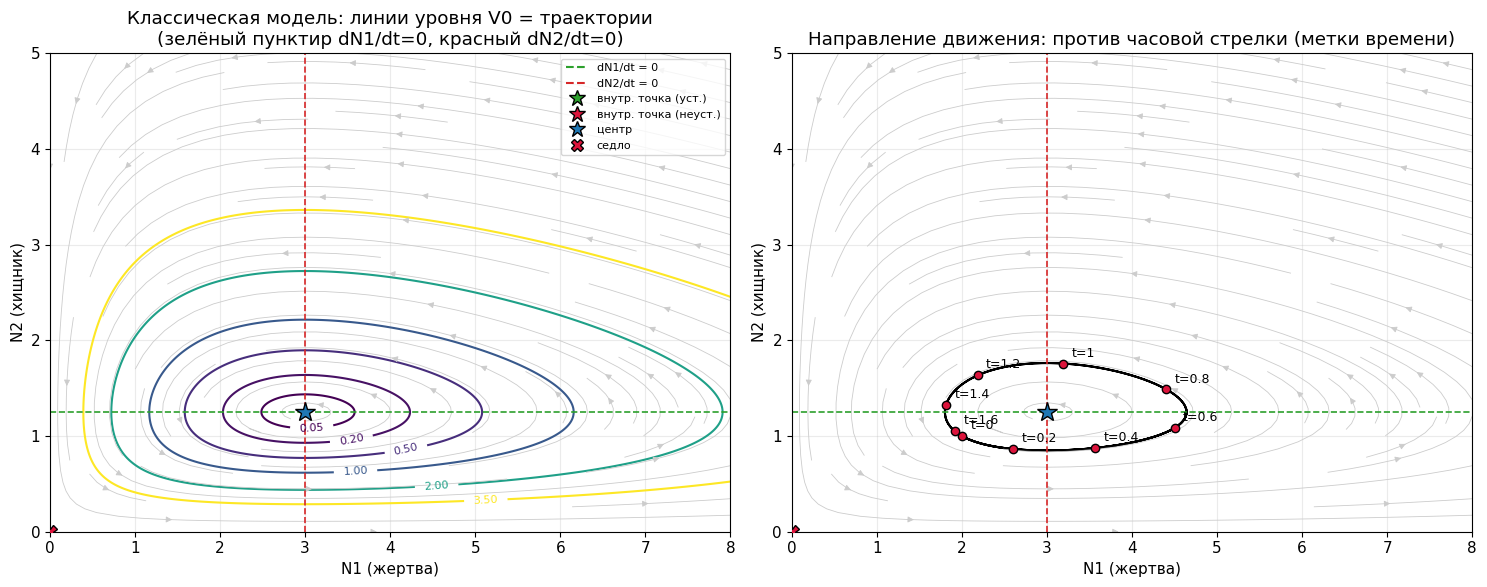

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
xlim, ylim = (0, 8), (0, 5)
X, Y = np.meshgrid(np.linspace(0.2, xlim[1], 500), np.linspace(0.15, ylim[1], 500))
Vgrid = V_lyap(X, Y, 0.0)
lv = [0.05, 0.2, 0.5, 1.0, 2.0, 3.5]
cs = ax[0].contour(X, Y, Vgrid, levels=lv, cmap='viridis', linewidths=1.5)
ax[0].clabel(cs, fmt='%.2f', fontsize=8)
phase_axes(ax[0], 0.0, xlim, ylim, ics=[], field=True, nullclines=True)
ax[0].set_title('Классическая модель: линии уровня V0 = траектории\n(зелёный пунктир dN1/dt=0, красный dN2/dt=0)')
legend_phase(ax[0], 'upper right')
# траектория с отметками времени, чтобы увидеть направление
t, N1, N2, _ = solve_lv(0.0, IC, 4, n=4000)
ax[1].plot(N1, N2, 'k', lw=1.5)
phase_axes(ax[1], 0.0, xlim, ylim, ics=[], field=True, nullclines=True)
for tm in [0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]:
    i = np.argmin(abs(t - tm)); ax[1].plot(N1[i], N2[i], 'o', color='crimson', mec='k', zorder=8)
    ax[1].annotate(f't={tm:g}', (N1[i], N2[i]), textcoords='offset points', xytext=(6, 5), fontsize=9)
ax[1].set_title('Направление движения: против часовой стрелки (метки времени)')
plt.tight_layout(); plt.show()

### 2.4. Поверхность $V_0$ и фазовый портрет

Функция $V_0(N_1,N_2)$ — «чаша» с единственным минимумом в центре (вблизи осей она уходит вверх, поэтому на рисунке ограничена по высоте). Линии уровня чаши, спроецированные вниз, — фазовые траектории.

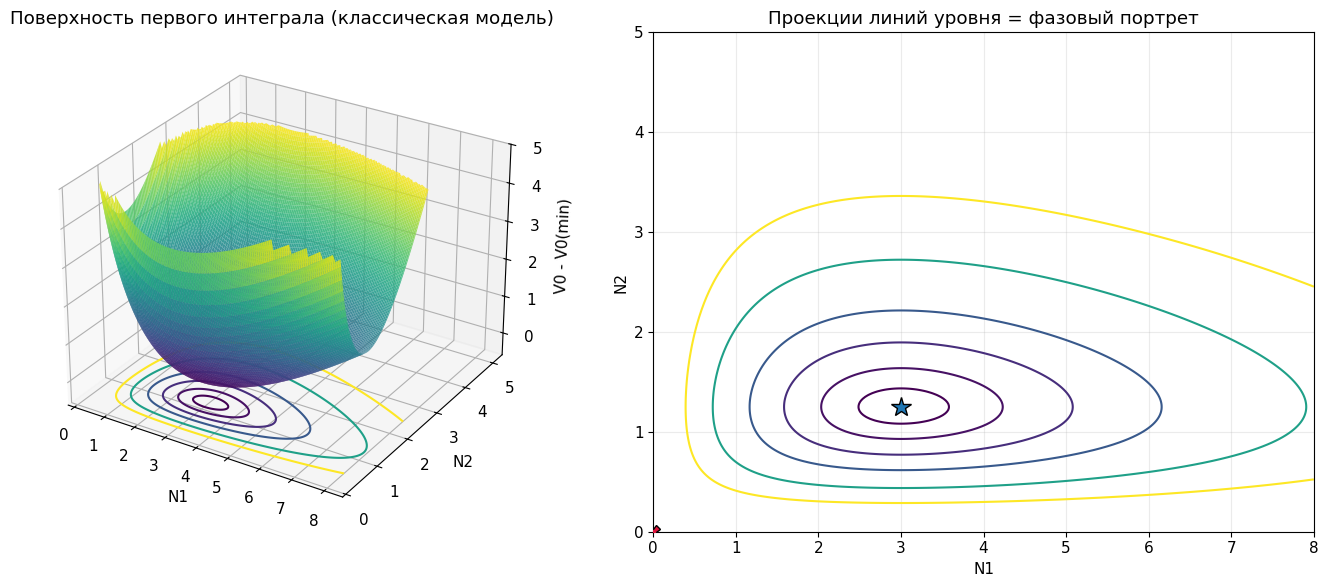

In [7]:
Xg, Yg = np.meshgrid(np.linspace(0.35, 8.0, 260), np.linspace(0.25, 5.0, 260))
Vg = V_lyap(Xg, Yg, 0.0)
zmax = 5.0
Vplot = np.where(Vg <= zmax, Vg, np.nan)
fig = plt.figure(figsize=(14, 6))
ax3 = fig.add_subplot(1, 2, 1, projection='3d')
ax3.plot_surface(Xg, Yg, Vplot, cmap='viridis', alpha=0.88, linewidth=0, rstride=2, cstride=2)
ax3.contour(Xg, Yg, Vg, levels=[0.05, 0.2, 0.5, 1, 2, 3.5], zdir='z', offset=-0.6, cmap='viridis')
ax3.set_zlim(-0.6, zmax); ax3.set_xlabel('N1'); ax3.set_ylabel('N2'); ax3.set_zlabel('V0 - V0(min)')
ax3.set_title('Поверхность первого интеграла (классическая модель)'); ax3.view_init(elev=28, azim=-58)
ax = fig.add_subplot(1, 2, 2)
ax.contour(Xg, Yg, Vg, levels=[0.05, 0.2, 0.5, 1, 2, 3.5], cmap='viridis')
mark_points(ax, 0.0, (0, 8), (0, 5)); ax.set_xlim(0, 8); ax.set_ylim(0, 5)
ax.set_xlabel('N1'); ax.set_ylabel('N2'); ax.set_title('Проекции линий уровня = фазовый портрет')
plt.tight_layout(); plt.show()

### 2.5. Решения: периодические колебания и сдвиг фаз

Для классической модели все решения периодичны. Графики $N_1(t)$, $N_2(t)$ при трёх разных начальных условиях показывают: чем дальше начальное условие от центра, тем больше **амплитуда** колебаний (и тем более они **несинусоидальны**); хищник отстаёт от жертвы примерно на четверть периода (пик хищника наступает после пика жертвы).

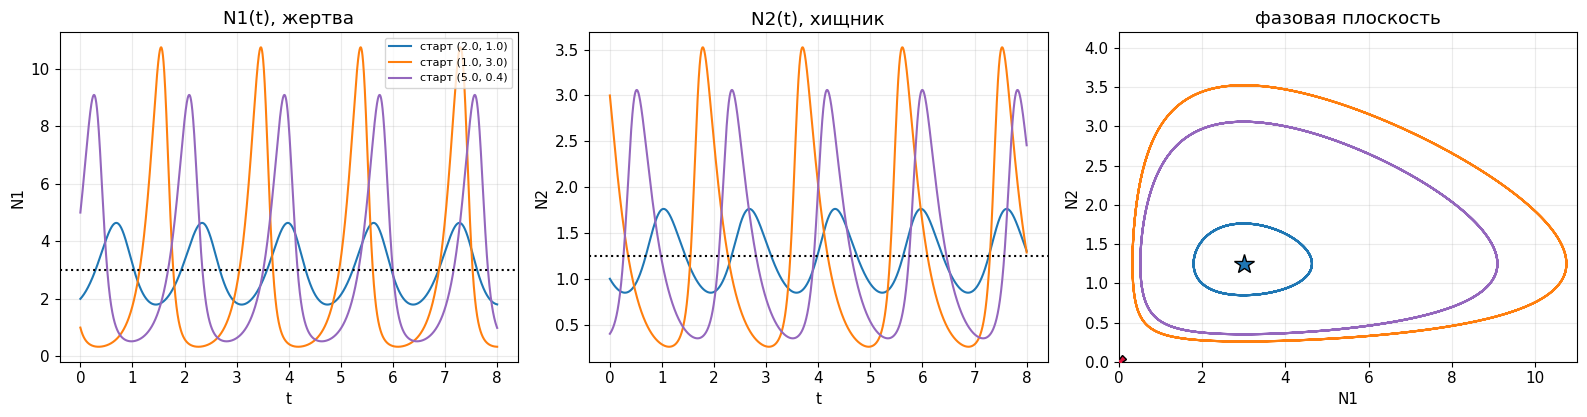

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for ic, c in zip(ICS, ['tab:blue', 'tab:orange', 'tab:purple']):
    t, N1, N2, _ = solve_lv(0.0, ic, 8, n=6000)
    ax[0].plot(t, N1, color=c, label=f'старт {ic}')
    ax[1].plot(t, N2, color=c)
    ax[2].plot(N1, N2, color=c)
ax[0].axhline(N_star0[0], color='k', ls=':'); ax[1].axhline(N_star0[1], color='k', ls=':')
ax[0].set_title('N1(t), жертва'); ax[1].set_title('N2(t), хищник'); ax[2].set_title('фазовая плоскость')
ax[0].set_xlabel('t'); ax[1].set_xlabel('t'); ax[2].set_xlabel('N1'); ax[0].set_ylabel('N1'); ax[1].set_ylabel('N2'); ax[2].set_ylabel('N2')
ax[0].legend(fontsize=8); mark_points(ax[2], 0.0, (0, 12), (0, 5))
ax[2].set_xlim(0, 11); ax[2].set_ylim(0, 4.2)
plt.tight_layout(); plt.show()

**Период зависит от амплитуды (неизохронность).** Для малых колебаний период $2\pi/\sqrt{\varepsilon_1\varepsilon_2}$, но у больших орбит он больше. Проверим численно: стартуем с $N_2(0)=N_2^*$ и разными $N_1(0)$ (то есть разными амплитудами) и найдём период по расстоянию между пиками $N_1(t)$.

   N1(0)    min N1    max N1    период
    3.05     2.951     3.050    1.6223
    3.50     2.550     3.500    1.6250
    4.00     2.182     4.000    1.6322
    5.00     1.621     5.000    1.6562
    6.00     1.219     6.000    1.6894
    8.00     0.703     8.000    1.7738


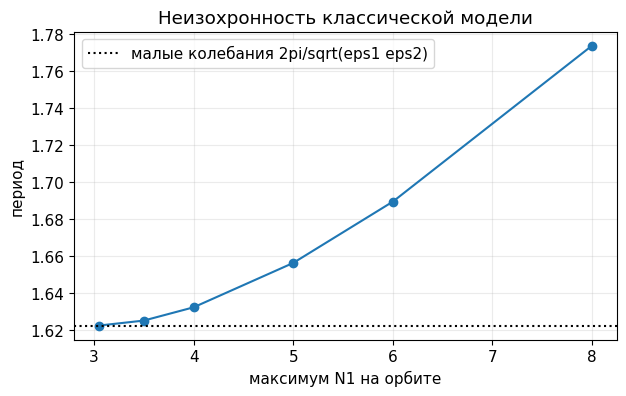

In [9]:
rows = []
for x0 in [N_star0[0] + 0.05, 3.5, 4.0, 5.0, 6.0, 8.0]:
    t, N1, N2, _ = solve_lv(0.0, (x0, N_star0[1]), 40, n=40000)
    pk, _ = find_peaks(N1)
    rows.append((x0, N1.min(), N1.max(), np.mean(np.diff(t[pk]))))
print(f'{"N1(0)":>8} {"min N1":>9} {"max N1":>9} {"период":>9}')
for r in rows: print(f'{r[0]:8.2f} {r[1]:9.3f} {r[2]:9.3f} {r[3]:9.4f}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([r[2] for r in rows], [r[3] for r in rows], 'o-')
ax.axhline(2*np.pi/np.sqrt(eps1*eps2), color='k', ls=':', label='малые колебания 2pi/sqrt(eps1 eps2)')
ax.set_xlabel('максимум N1 на орбите'); ax.set_ylabel('период'); ax.legend(); ax.set_title('Неизохронность классической модели')
plt.show()

**Выводы по классической модели.** Единственная внутренняя точка — центр; все положительные решения периодичны, их амплитуда и период определяются начальными условиями (семейство замкнутых орбит, а не один предельный цикл); система консервативна по отношению к $V_0$. Это идеальная, но «хрупкая» картина: ниже показано, как её меняет любая поправка.

---
## 3. Модель с логистической поправкой: особые точки и их тип

### 3.1. Особые точки (символьно)

In [10]:
sols = sp.solve([f1, f2], [x1, x2], dict=True)
labels = ['начало координат', 'только хищник', 'только жертва', 'внутренняя (сосуществование)']
J = sp.Matrix([f1, f2]).jacobian([x1, x2])
display(Math(r'J=' + sp.latex(J)))
for s, lab in zip(sols, labels):
    display(Math(r'\text{' + lab + r'}:\quad (N_1^*,N_2^*)=(' + sp.latex(sp.simplify(s[x1])) + r',\ ' + sp.latex(sp.simplify(s[x2])) + r')'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 3.2. Собственные значения во всех точках

Для трёх «граничных» точек матрица Якоби треугольная, и собственные значения читаются сразу.

In [11]:
for s, lab in zip(sols[:3], labels[:3]):
    Js = sp.simplify(J.subs(s))
    display(Math(r'\text{' + lab + r'}:\ J=' + sp.latex(Js) + r',\quad \lambda=' + sp.latex(list(Js.eigenvals().keys()))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Вывод (для $\varepsilon_i,\gamma_i>0$):

| Точка | Собственные значения | Тип в квадранте при $\alpha\in[-1,1]$ |
|---|---|---|
| $(0,0)$ | $\varepsilon_1>0,\ -\varepsilon_2<0$ | седло при любом $\alpha$ |
| $(\varepsilon_1/\alpha,\ 0)$, $\alpha>0$ | $-\varepsilon_1<0,\ \ \gamma_2\varepsilon_1/\alpha-\varepsilon_2$ | седло при $\alpha<\gamma_2\varepsilon_1/\varepsilon_2$ (для варианта 10 это $\alpha<5/3$) |
| $(0,\ -\varepsilon_2/\alpha)$, $\alpha<0$ | $\varepsilon_2>0,\ \ \varepsilon_1+\gamma_1\varepsilon_2/\alpha$ | седло при $\vert\alpha\vert<\gamma_1\varepsilon_2/\varepsilon_1$ (для варианта 10 это $\vert\alpha\vert<2{,}4$) |

Точка $(\varepsilon_1/\alpha,0)$ при $\alpha<0$ и точка $(0,-\varepsilon_2/\alpha)$ при $\alpha>0$ лежат вне квадранта (отрицательные численности), на динамику не влияют. При $\alpha\to0$ осевые точки уходят на бесконечность — в классической модели их нет.

### 3.3. Внутренняя точка: компактная форма

Подставим в матрицу Якоби условия равновесия $\varepsilon_1=\gamma_1N_2^*+\alpha N_1^*$, $\varepsilon_2=\gamma_2N_1^*-\alpha N_2^*$ (то есть выразим параметры через координаты точки). Получится компактная матрица из раздела 1.3, а $T$, $D$ — простые выражения.

In [12]:
s1, s2 = sp.symbols('N1s N2s', positive=True)
sub_eq = {e1: g1*s2 + al*s1, e2: g2*s1 - al*s2}
Jstar = sp.simplify(J.subs(sub_eq).subs({x1: s1, x2: s2}))
display(Math(r'J^*=' + sp.latex(Jstar)))
display(Math(r'T=\operatorname{tr}J^*=' + sp.latex(sp.simplify(Jstar.trace())) + r',\qquad D=\det J^*=' + sp.latex(sp.factor(sp.simplify(Jstar.det())))))
display(Math(r'\Delta=T^2-4D,\quad \lambda=\frac T2\pm\sqrt{\frac{T^2}{4}-D}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Итак, $T=-\alpha(N_1^*+N_2^*)$ и $D=N_1^*N_2^*(\alpha^2+\gamma_1\gamma_2)>0$: **знак вещественной части корней противоположен знаку $\alpha$**. $D>0$ всегда, поэтому седловой тип внутренней точки невозможен.

### 3.4. Функция Ляпунова: символьная проверка

Проверим формулу $\dot V=-\alpha(\gamma_2\Delta N_1^2+\gamma_1\Delta N_2^2)$ из раздела 1.4, подставив в производную условия равновесия.

In [13]:
V = g2*(x1 - s1*sp.log(x1)) + g1*(x2 - s2*sp.log(x2))       # константа не влияет на производную
Vdot = sp.diff(V, x1)*f1 + sp.diff(V, x2)*f2
Vdot_eq = sp.simplify(Vdot.subs(sub_eq))
claim = -al*(g2*(x1 - s1)**2 + g1*(x2 - s2)**2)
display(Math(r'\dot V=' + sp.latex(sp.factor(Vdot_eq))))
print('Разность с формулой  -alpha*(gamma2*dN1^2 + gamma1*dN2^2):', sp.simplify(Vdot_eq - claim))

<IPython.core.display.Math object>

Разность с формулой  -alpha*(gamma2*dN1^2 + gamma1*dN2^2): 0


Разность равна нулю, формула верна.

### 3.5. Тип внутренней точки при $\alpha\in[-1,1]$

Таблица и графики показывают зависимость от $\alpha$: координаты точки, след $T$, определитель $D$, дискриминант $\Delta$, собственные значения и тип.

In [14]:
print(f'{"alpha":>6} {"N1*":>7} {"N2*":>7} {"T":>8} {"D":>8} {"Delta":>9}  {"lambda":28s}  тип')
for a in ALPHAS:
    N, T, D, lam, kind = interior_info(a)
    print(f'{a:6.2f} {N[0]:7.3f} {N[1]:7.3f} {T:8.3f} {D:8.3f} {T*T-4*D:9.2f}  {fmt_lam(lam):28s}  {kind}')
a_lo, a_hi = -gam1*eps2/eps1, gam2*eps1/eps2
print(f'\nВнутренняя точка лежит в квадранте при  {a_lo:.3f} < alpha < {a_hi:.3f}  (отрезок [-1, 1] целиком внутри).')

 alpha     N1*     N2*        T        D     Delta  lambda                        тип
 -1.00   1.400   1.600    3.000   11.200    -35.80  +1.500+2.992i,  +1.500-2.992i  неустойчивый фокус
 -0.50   2.235   1.529    1.882   14.529    -54.57  +0.941+3.694i,  +0.941-3.694i  неустойчивый фокус
 -0.18   2.753   1.374    0.743   15.250    -60.45  +0.371+3.887i,  +0.371-3.887i  неустойчивый фокус
 -0.05   2.936   1.287    0.211   15.119    -60.43  +0.106+3.887i,  +0.106-3.887i  неустойчивый фокус
  0.00   3.000   1.250    0.000   15.000    -60.00  +0.000+3.873i,  +0.000-3.873i  центр
  0.05   3.061   1.212   -0.214   14.844    -59.33  -0.107+3.851i,  -0.107-3.851i  устойчивый фокус
  0.18   3.199   1.106   -0.775   14.268    -56.47  -0.387+3.757i,  -0.387-3.757i  устойчивый фокус
  0.50   3.412   0.824   -2.118   11.941    -43.28  -1.059+3.289i,  -1.059-3.289i  устойчивый фокус
  1.00   3.400   0.400   -3.800    6.800    -12.76  -1.900+1.786i,  -1.900-1.786i  устойчивый фокус

Внутренняя точка

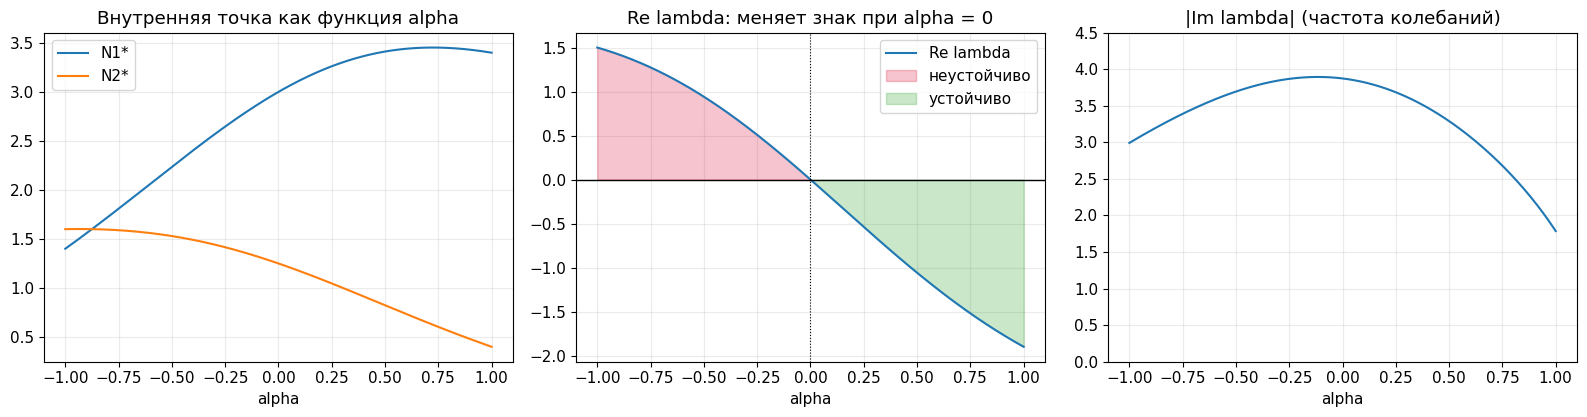

In [15]:
al_grid = np.linspace(-1, 1, 401)
Ns = np.array([equilibrium(a) for a in al_grid])
Js_ = [jacobian_at(a, N) for a, N in zip(al_grid, Ns)]
lam = np.array([np.linalg.eigvals(J_) for J_ in Js_])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(al_grid, Ns[:, 0], label='N1*'); ax[0].plot(al_grid, Ns[:, 1], label='N2*')
ax[0].set_title('Внутренняя точка как функция alpha'); ax[0].set_xlabel('alpha'); ax[0].legend()
ax[1].plot(al_grid, lam[:, 0].real, label='Re lambda'); ax[1].axhline(0, color='k', lw=1)
ax[1].axvline(0, color='k', lw=0.8, ls=':')
ax[1].fill_between(al_grid, lam[:, 0].real, 0, where=lam[:, 0].real > 0, color='crimson', alpha=.25, label='неустойчиво')
ax[1].fill_between(al_grid, lam[:, 0].real, 0, where=lam[:, 0].real < 0, color='tab:green', alpha=.25, label='устойчиво')
ax[1].set_title('Re lambda: меняет знак при alpha = 0'); ax[1].set_xlabel('alpha'); ax[1].legend()
ax[2].plot(al_grid, np.abs(lam[:, 0].imag)); ax[2].set_title('|Im lambda| (частота колебаний)'); ax[2].set_xlabel('alpha')
ax[2].set_ylim(0, 4.5)
plt.tight_layout(); plt.show()

**Вывод по типу точки.** При всех $\alpha\in[-1,1]$, $\alpha\ne0$, дискриминант $\Delta<0$: внутренняя точка — **фокус**. Знак $\operatorname{Re}\lambda=T/2=-\alpha(N_1^*+N_2^*)/2$ противоположен знаку $\alpha$:

* $\alpha>0$ — **устойчивый фокус**;
* $\alpha<0$ — **неустойчивый фокус**;
* $\alpha=0$ — **центр**.

В точке $\alpha=0$ вещественная часть корней пересекает ноль с ненулевой скоростью ($\frac{d\operatorname{Re}\lambda}{d\alpha}\big|_{\alpha=0}=-\frac{N_1^*+N_2^*}{2}\approx-2{,}1$ для варианта 10), но при этом не рождается предельный цикл, как в обычной бифуркации Андронова–Хопфа: вместо этого в самой точке бифуркации существует **целое семейство замкнутых орбит**. Это вырожденная (консервативная) бифуркация Хопфа, и именно она определяет чувствительность классической модели.

Также видно: частота колебаний $|\operatorname{Im}\lambda|$ почти не зависит от $\alpha$ для малых $|\alpha|$ (около $\sqrt{15}\approx3{,}87$), а скорость затухания или роста растёт линейно с $\alpha$.

---
## 4. Вариант 10 при $\alpha=0{,}18$: решения и фазовый портрет

Три панели: графики $N_1(t)$, $N_2(t)$ с пунктиром равновесных значений; фазовая плоскость с нуль-изоклинами, полем направлений и тремя траекториями; функция Ляпунова $V(t)$ (логарифмическая шкала).

alpha = 0.18: внутренняя точка N* = (3.1991, 1.1060), T = -0.7749, D = 14.2679
собственные значения: -0.387+3.757i,  -0.387-3.757i  ->  устойчивый фокус
время релаксации 1/|Re lambda| = 2.58, период колебаний 2*pi/|Im lambda| = 1.672


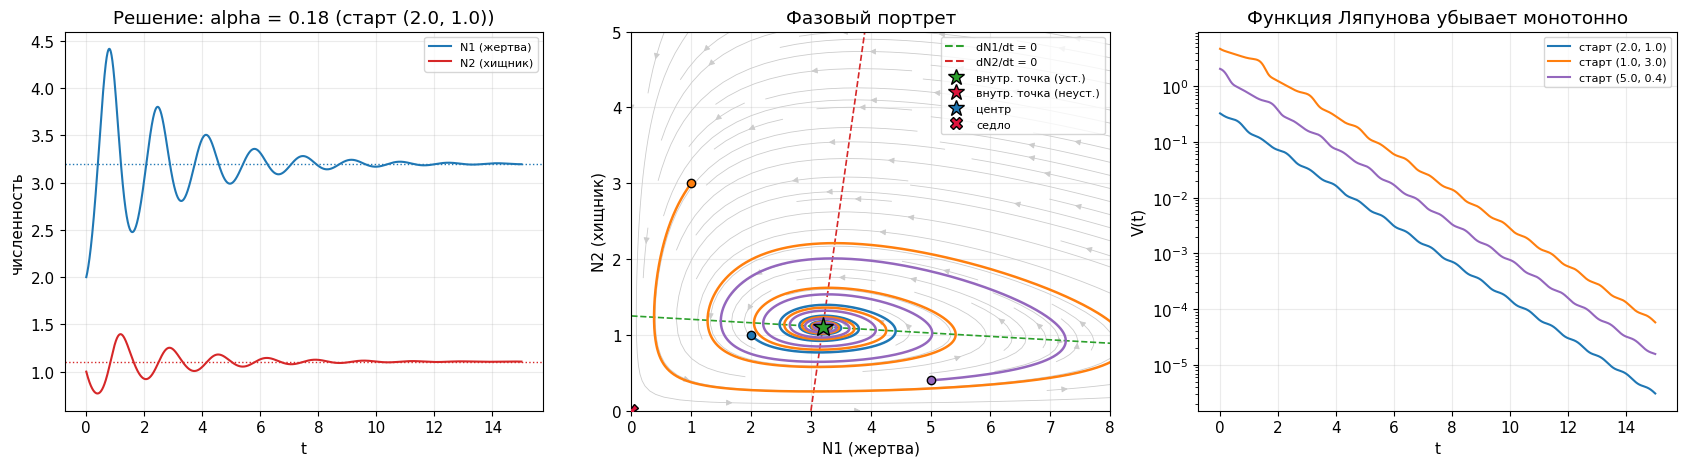

In [16]:
a = ALPHA_VAR
N, T_, D_, lam, kind = interior_info(a)
print(f'alpha = {a}: внутренняя точка N* = ({N[0]:.4f}, {N[1]:.4f}), T = {T_:.4f}, D = {D_:.4f}')
print(f'собственные значения: {fmt_lam(lam)}  ->  {kind}')
print(f'время релаксации 1/|Re lambda| = {1/abs(lam[0].real):.2f}, период колебаний 2*pi/|Im lambda| = {2*np.pi/abs(lam[0].imag):.3f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
series_axes(ax[0], a, IC, T=15); ax[0].legend(fontsize=8); ax[0].set_title(f'Решение: alpha = {a} (старт {IC})')
phase_axes(ax[1], a, (0, 8), (0, 5), T=15); legend_phase(ax[1], 'upper right'); ax[1].set_title('Фазовый портрет')
for ic, c in zip(ICS, ['tab:blue', 'tab:orange', 'tab:purple']):
    t, N1, N2, _ = solve_lv(a, ic, 15, n=6000)
    ax[2].semilogy(t, V_lyap(N1, N2, a), color=c, label=f'старт {ic}')
ax[2].set_xlabel('t'); ax[2].set_ylabel('V(t)'); ax[2].set_title('Функция Ляпунова убывает монотонно'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

Что видно:

* из любого начального условия решение выходит на **постоянные** значения $N^*=(3{,}199;\ 1{,}106)$: затухающие колебания жертвы и хищника с характерным временем затухания около $1/|\operatorname{Re}\lambda|\approx2{,}6$ и периодом около $1{,}67$;
* на фазовой плоскости траектории — **спирали**, закручивающиеся в устойчивый фокус; нуль-изоклины уже не горизонтальная и вертикальная прямые, как в классической модели, а **наклонные** (поправка $\alpha$ наклоняет их);
* функция $V$ убывает монотонно, но неравномерно: быстрее там, где $\Delta N$ велики.

**Проверка формулы $\dot V$.** Сравним производную $V$, посчитанную прямо вдоль численного решения, с формулой $-\alpha(\gamma_2\Delta N_1^2+\gamma_1\Delta N_2^2)$.

In [17]:
t, N1, N2, _ = solve_lv(ALPHA_VAR, IC, 15, n=6000)
d1 = Vdot_direct(N1, N2, ALPHA_VAR); d2 = Vdot_formula(N1, N2, ALPHA_VAR)
print(f'максимальная разность |dV/dt прямо - dV/dt по формуле| = {np.abs(d1 - d2).max():.2e}  (масштаб |dV/dt| ~ {np.abs(d1).max():.2f})')
V = V_lyap(N1, N2, ALPHA_VAR)
print(f'V убывает монотонно: {bool(np.all(np.diff(V) <= 1e-12))};  V(0) = {V[0]:.4f},  V(15) = {V[-1]:.2e}')
dVdt_fd = np.gradient(V, t)
print(f'численная производная V (конечные разности) vs формула: макс. разность {np.abs(dVdt_fd[5:-5] - d2[5:-5]).max():.2e}')

максимальная разность |dV/dt прямо - dV/dt по формуле| = 9.99e-16  (масштаб |dV/dt| ~ 0.27)
V убывает монотонно: True;  V(0) = 0.3253,  V(15) = 3.07e-06
численная производная V (конечные разности) vs формула: макс. разность 8.04e-06


---
## 5. Серия значений $\alpha\in[-1,1]$: графики решений и фазовые портреты (пункт 1)

Для девяти значений $\alpha$ (от $-1$ до $1$, включая $0$ и значение варианта $0{,}18$) строим фазовые портреты (три начальных условия, нуль-изоклины, поле направлений) и графики решений (одно начальное условие). Звезда на портрете: зелёная — устойчивая внутренняя точка, красная — неустойчивая, синяя — центр; красные крестики — седла.

### 5.1. Фазовые портреты

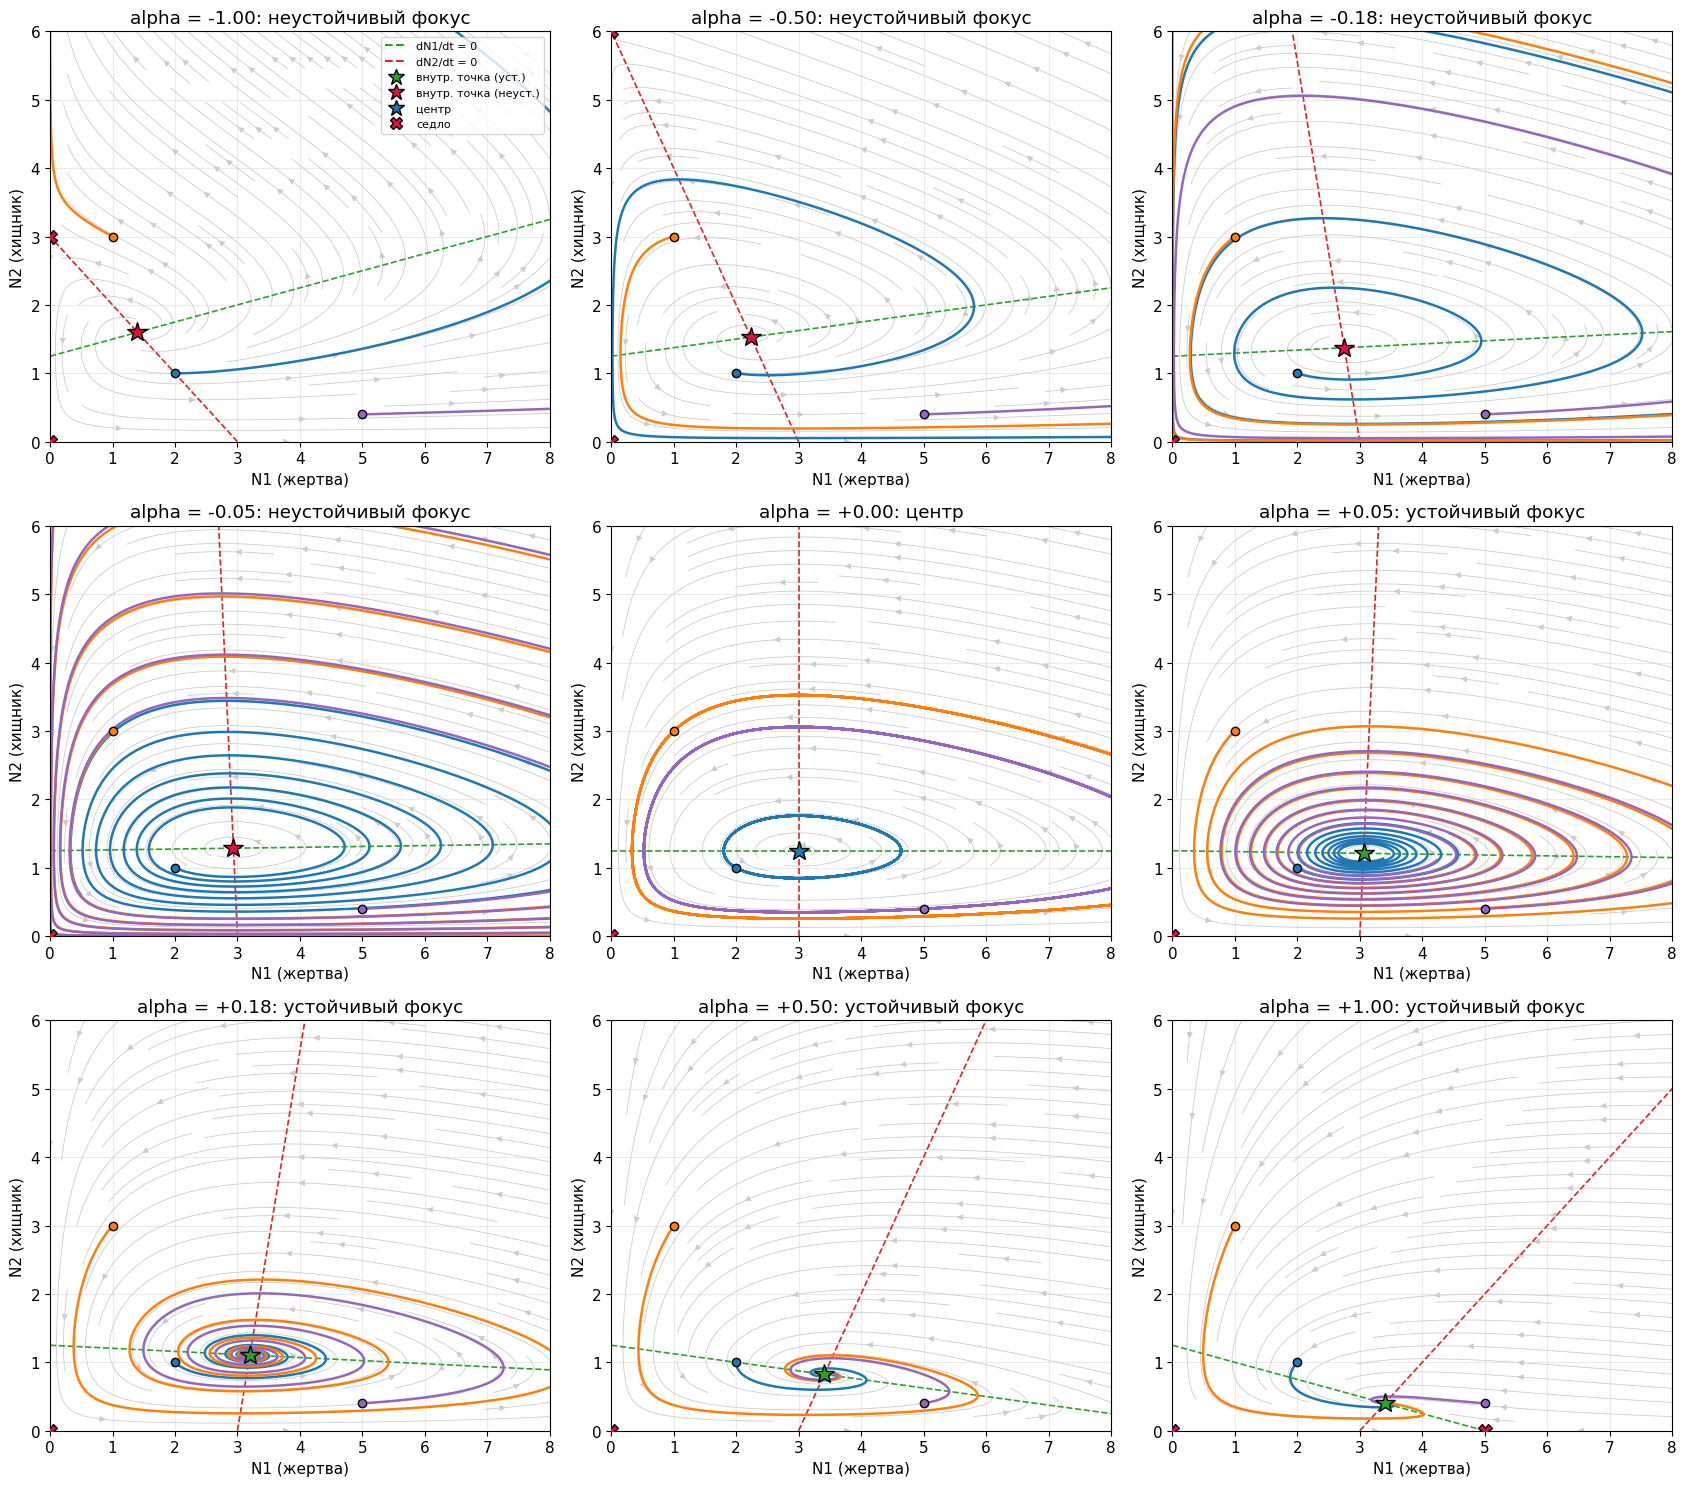

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(17, 15))
for ax, a in zip(axes.ravel(), ALPHAS):
    phase_axes(ax, a, (0, 8), (0, 6), T=12)
    N, T_, D_, lam, kind = interior_info(a)
    ax.set_title(f'alpha = {a:+.2f}: {kind}')
legend_phase(axes[0, 0], 'upper right')
plt.tight_layout(); plt.show()

**Как читать сетку.**

* $\alpha=0$ (центр сетки): замкнутые орбиты вокруг центра.
* $\alpha>0$ (нижний ряд справа, и $\alpha=0{,}05$): траектории закручиваются **внутрь**, в устойчивый фокус; чем больше $\alpha$, тем быстрее сходимость и тем «круче» спираль. При $\alpha=1$ хищник уже заметно подавлен: равновесное значение $N_2^*=0{,}4$.
* $\alpha<0$ (верхний ряд и $\alpha=-0{,}05$): траектории раскручиваются **наружу** и уходят к левому верхнему краю: жертва стремится к нулю, хищник растёт (за конечное время неограниченно). При малом $|\alpha|$ раскрутка медленная (оборотов много), при $\alpha=-1$ — всего пол-оборота.
* Осевые седла: при $\alpha>0$ седло на оси $N_1$ (далеко справа, за пределами окна при малых $\alpha$), при $\alpha<0$ седло на оси $N_2$ (при $\alpha=-1$: точка $(0;3)$).

### 5.2. Графики решений

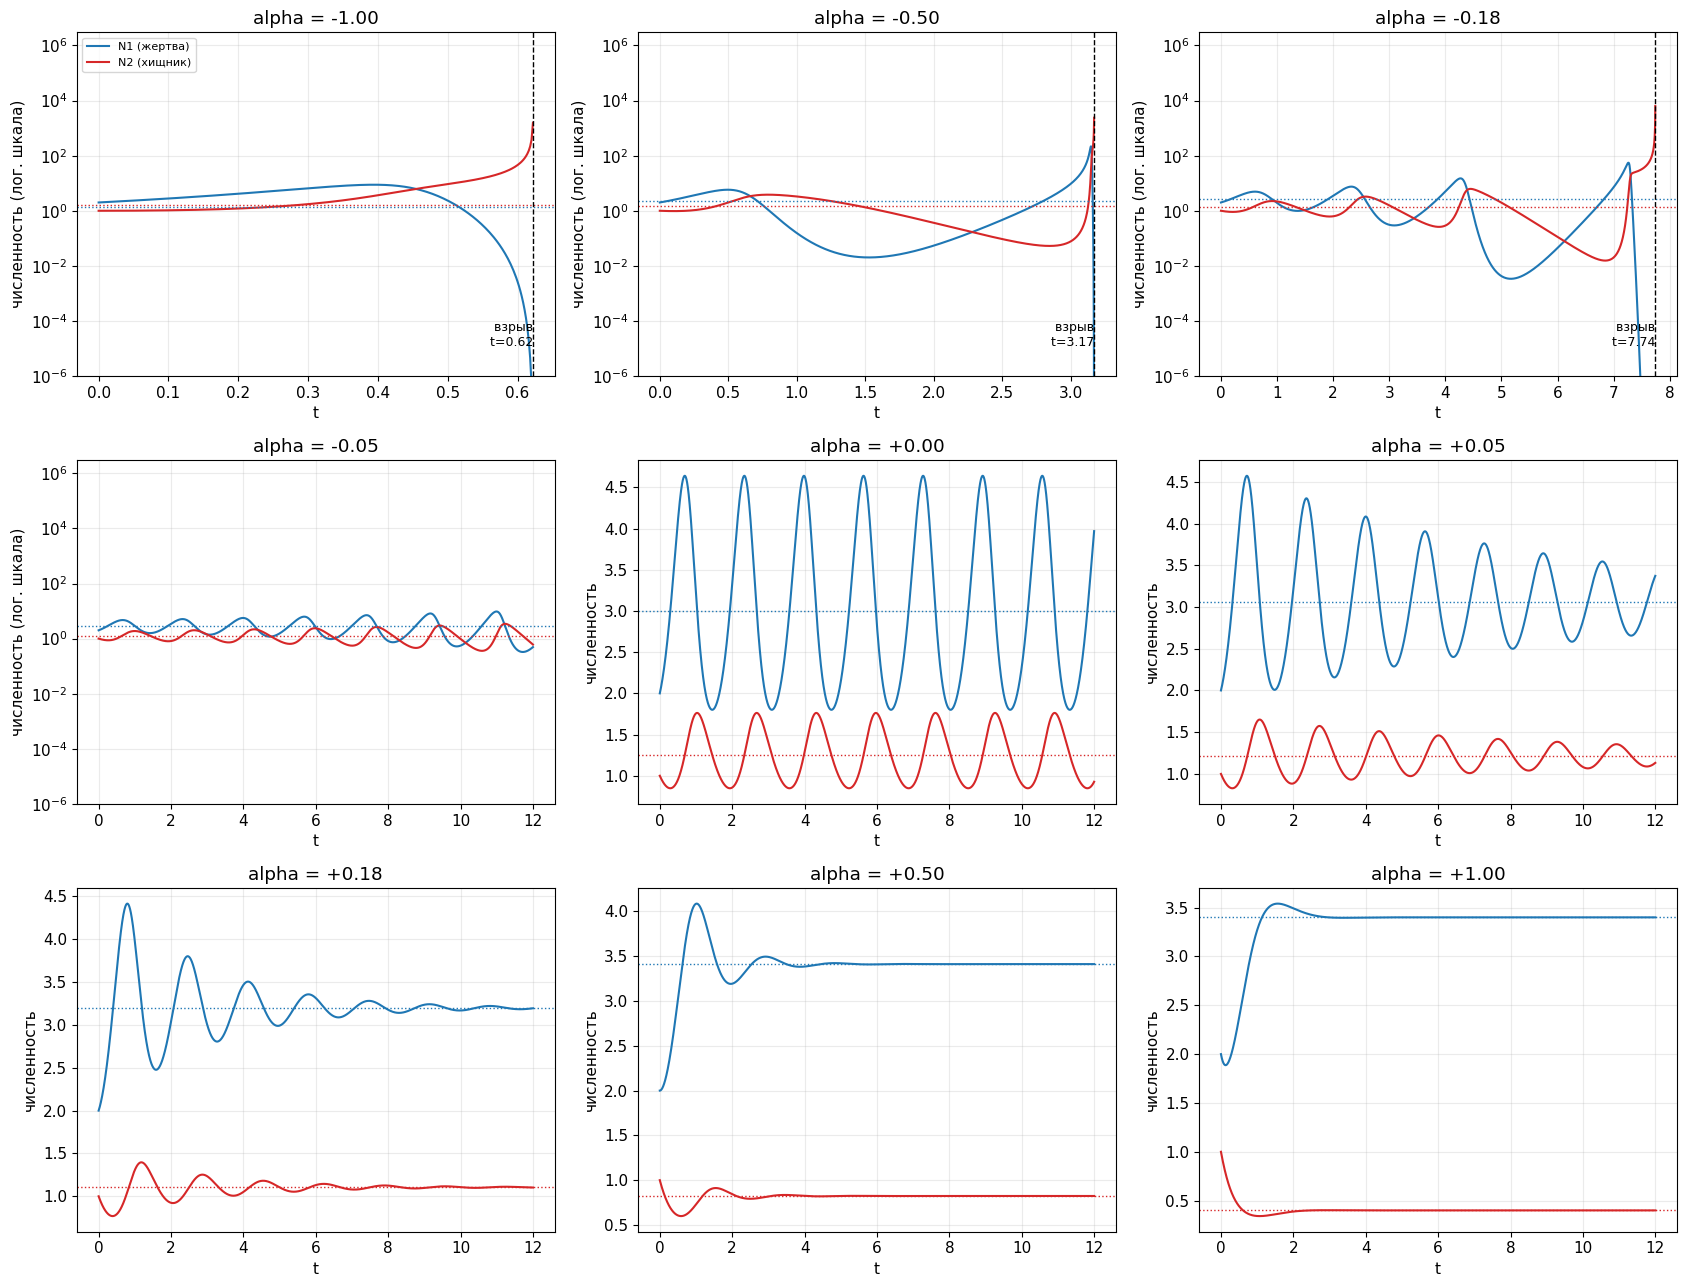

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
blow_times = {}
for ax, a in zip(axes.ravel(), ALPHAS):
    tb = series_axes(ax, a, IC, T=12)
    blow_times[a] = tb
    ax.set_title(f'alpha = {a:+.2f}')
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Что видно на графиках.**

* $\alpha=0$: незатухающие периодические колебания обеих популяций, хищник отстаёт от жертвы.
* $\alpha>0$: колебания **затухают**, решение выходит на постоянные значения (пунктиры). Чем больше $\alpha$, тем быстрее.
* $\alpha<0$: колебания **нарастают**, шкала логарифмическая. Жертва падает до практически нулевых значений, хищник за конечное время «взрывается» (вертикальная пунктирная линия). Чем больше $|\alpha|$, тем быстрее. При $\alpha=-0{,}05$ взрыв происходит позже, чем закончилось окно $t\le12$ (около $t\approx53$–$61$, см. таблицу ниже), поэтому на графике виден лишь рост размаха колебаний.

Моменты взрыва и глубина падения жертвы:

In [20]:
import warnings
print(f'{"alpha":>6} {"старт":>12} {"время взрыва":>13} {"min N1 до взрыва":>18}')
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)          # у самого взрыва шаг решателя огромный
    for a in [x for x in ALPHAS if x < 0] + [-0.01]:
        for ic in ICS[:2]:
            t, N1, N2, tb = solve_lv(a, ic, 1000, n=20000)
            m = N1.min()
            print(f'{a:6.2f} {str(ic):>12} {tb:13.3f} {("< 1e-100" if m < 1e-100 else format(m, ".2e")):>18}')

 alpha        старт  время взрыва   min N1 до взрыва
 -1.00   (2.0, 1.0)         0.623           2.70e-03
 -1.00   (1.0, 3.0)         0.804           8.28e-11
 -0.50   (2.0, 1.0)         3.171           2.03e-02
 -0.50   (1.0, 3.0)         1.881           1.69e-02
 -0.18   (2.0, 1.0)         7.744           3.24e-27
 -0.18   (1.0, 3.0)         5.080           1.43e-29


 -0.05   (2.0, 1.0)        60.645           5.34e-50
 -0.05   (1.0, 3.0)        52.706           1.45e-56


 -0.01   (2.0, 1.0)       267.002           < 1e-100


 -0.01   (1.0, 3.0)       325.135           < 1e-100


---
## 6. Сравнение $\alpha$ противоположных знаков (пункт 2)

Возьмём $\alpha=+0{,}18$ (значение варианта) и $\alpha=-0{,}18$ и сравним одно и то же начальное условие. Верхний ряд — $\alpha>0$, нижний — $\alpha<0$; слева $N_i(t)$, в центре фазовая плоскость, справа функция Ляпунова.

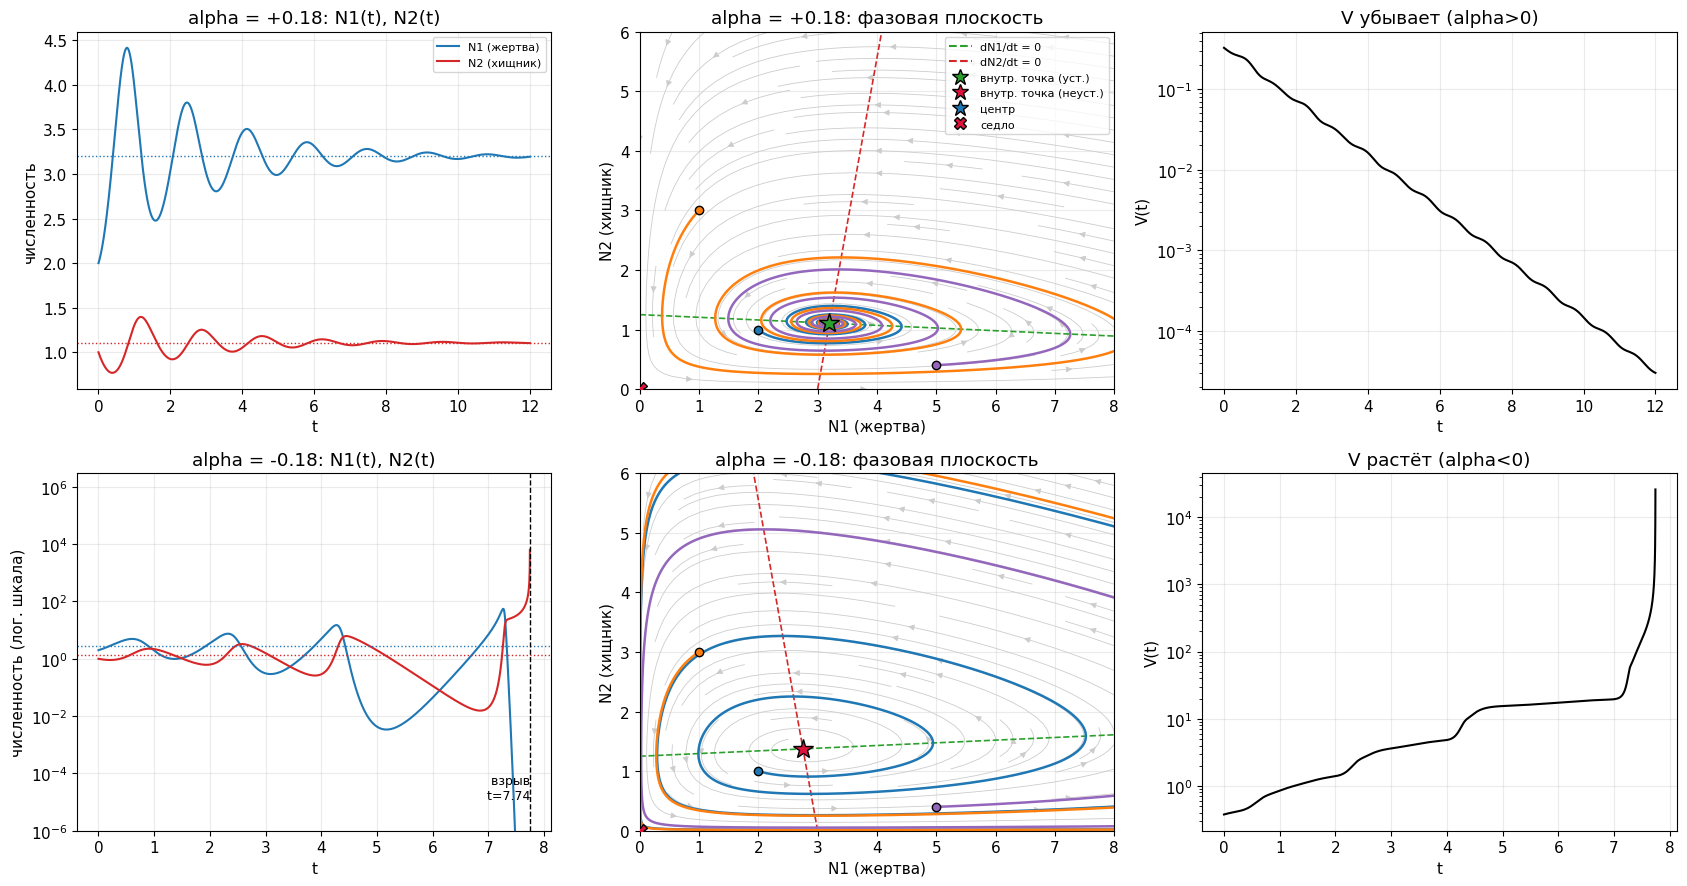

In [21]:
a_p, a_m = ALPHA_VAR, -ALPHA_VAR
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for row, a in enumerate([a_p, a_m]):
    tb = series_axes(ax[row, 0], a, IC, T=12); ax[row, 0].set_title(f'alpha = {a:+.2f}: N1(t), N2(t)')
    phase_axes(ax[row, 1], a, (0, 8), (0, 6), T=12); ax[row, 1].set_title(f'alpha = {a:+.2f}: фазовая плоскость')
    t, N1, N2, tb = solve_lv(a, IC, 12, n=6000)
    ax[row, 2].semilogy(t, V_lyap(N1, N2, a), color='k')
    ax[row, 2].set_xlabel('t'); ax[row, 2].set_ylabel('V(t)')
    ax[row, 2].set_title('V убывает (alpha>0)' if a > 0 else 'V растёт (alpha<0)')
ax[0, 0].legend(fontsize=8); legend_phase(ax[0, 1], 'upper right')
plt.tight_layout(); plt.show()

### 6.1. Сводная таблица для противоположных знаков

Для обоих значений посчитаем равновесие, собственные значения и сопоставим со временем жизни решения.

In [22]:
print(f'{"alpha":>7} {"N*":>18} {"lambda":>26}  {"тип":24s} {"что с решением"}')
for a in [a_p, a_m]:
    N, T_, D_, lam, kind = interior_info(a)
    t, N1, N2, tb = solve_lv(a, IC, 4000, n=20000)
    fate = ('сходится к N*' if tb is None else f'взрыв при t = {tb:.2f}, N1 -> {N1.min():.0e}')
    print(f'{a:+7.2f} ({N[0]:.3f}, {N[1]:.3f}) {fmt_lam(lam):>26}  {kind:24s} {fate}')

  alpha                 N*                     lambda  тип                      что с решением


  +0.18 (3.199, 1.106) -0.387+3.757i,  -0.387-3.757i  устойчивый фокус         сходится к N*
  -0.18 (2.753, 1.374) +0.371+3.887i,  +0.371-3.887i  неустойчивый фокус       взрыв при t = 7.74, N1 -> 2e-14


### 6.2. Проверка скорости роста и затухания линеаризацией

Теория (разд. 1.3) предсказывает, что вблизи внутренней точки амплитуда колебаний меняется как $e^{\operatorname{Re}\lambda\,t}$, то есть функция $V$ (пропорциональная квадрату амплитуды) — как $e^{Tt}$, а период — как $2\pi/\sqrt{D-T^2/4}$. Проверим численно: стартуем с малого отклонения от равновесия, чтобы работала линеаризация, и сравним наклон $\ln V$ и период пиков с предсказанием.

In [23]:
print(f'{"alpha":>6} | {"T (теория)":>11} {"наклон ln V":>12} | {"период (теор.)":>15} {"период (числ.)":>15}')
for a in [-0.18, -0.05, 0.05, 0.18, 0.5]:
    s = equilibrium(a); J_ = jacobian_at(a, s); Tr, Dt = np.trace(J_), np.linalg.det(J_)
    t, N1, N2, tb = solve_lv(a, (s[0] + 0.01, s[1]), T=5/abs(Tr), n=40000)
    V = V_lyap(N1, N2, a); slope = np.polyfit(t, np.log(V), 1)[0]
    pk, _ = find_peaks(N1)
    per_num = np.mean(np.diff(t[pk])) if len(pk) >= 3 else np.nan
    per_th = 2*np.pi/np.sqrt(Dt - Tr**2/4)
    print(f'{a:6.2f} | {Tr:11.4f} {slope:12.4f} | {per_th:15.4f} {per_num:15.4f}')

 alpha |  T (теория)  наклон ln V |  период (теор.)  период (числ.)
 -0.18 |      0.7428       0.7424 |          1.6163          1.6168
 -0.05 |      0.2111       0.2111 |          1.6165          1.6167
  0.05 |     -0.2136      -0.2136 |          1.6314          1.6315
  0.18 |     -0.7749      -0.7741 |          1.6722          1.6721
  0.50 |     -2.1176      -2.1168 |          1.9101             nan


Наклон $\ln V$ совпадает с $T$ (с точностью до нескольких знаков), периоды — с $2\pi/\sqrt{D-T^2/4}$ там, где пиков достаточно для оценки. Это подтверждает, что линеаризация правильно описывает поведение вблизи внутренней точки и что знак $\alpha$ определяет, затухают колебания или нарастают.

### 6.3. Вывод для $\alpha$ противоположных знаков

| | $\alpha>0$ (изъятие) | $\alpha<0$ (пополнение) |
|---|---|---|
| Внутренняя точка | **устойчивый фокус** ($T<0$) | **неустойчивый фокус** ($T>0$) |
| Функция Ляпунова | $\dot V<0$: убывает | $\dot V>0$: растёт |
| Колебания | затухают, амплитуда $\propto e^{-|{\rm Re}\lambda|t}$ | нарастают, амплитуда $\propto e^{|{\rm Re}\lambda|t}$ |
| Итог | устойчивое **сосуществование** видов с постоянными численностями $N^*$; точка притягивает все положительные решения | жертва стремится к нулю, хищник за **конечное время** уходит на бесконечность («взрыв»); внутренняя точка отталкивает |
| Время процесса | порядка $1/|\operatorname{Re}\lambda|$ (для 0,18: около 2,6) | время до взрыва растёт при $|\alpha|\to0$ как $\sim1/|\alpha|$ (раздел 5) |

Содержательно: изъятие, пропорциональное квадрату численности, играет роль самоограничения и стабилизирует систему. Пополнение, пропорциональное квадрату численности, — положительная обратная связь без насыщения; в рамках модели оно приводит к взрывному росту одного вида и вымиранию другого. Для реальной задачи это значит, что при $\alpha<0$ модель применима лишь на ограниченном промежутке времени; для долгосрочного прогноза нужно добавить механизм насыщения.

---
## 7. Чувствительность классической модели к малым изменениям вида уравнений (пункт 3)

Вопрос: если слегка изменить правые части классической модели (например, добавить поправку $\alpha$ сколь угодно малой величины), сильно ли изменится картина? Рассмотрим четыре независимых проверки.

### 7.1. Поправка $\alpha=\pm0{,}001,\pm0{,}01,\pm0{,}05$: растёт ли разница с классическим решением?

Возьмём одно и то же начальное условие и сравним решение с поправкой с решением классической модели. Левая панель — расстояние между решениями как функция времени (логарифмическая шкала), правая — фазовые портреты при $\alpha=0$ и $\alpha=\pm0{,}05$ на длинном промежутке ($t\le60$, около 37 периодов).

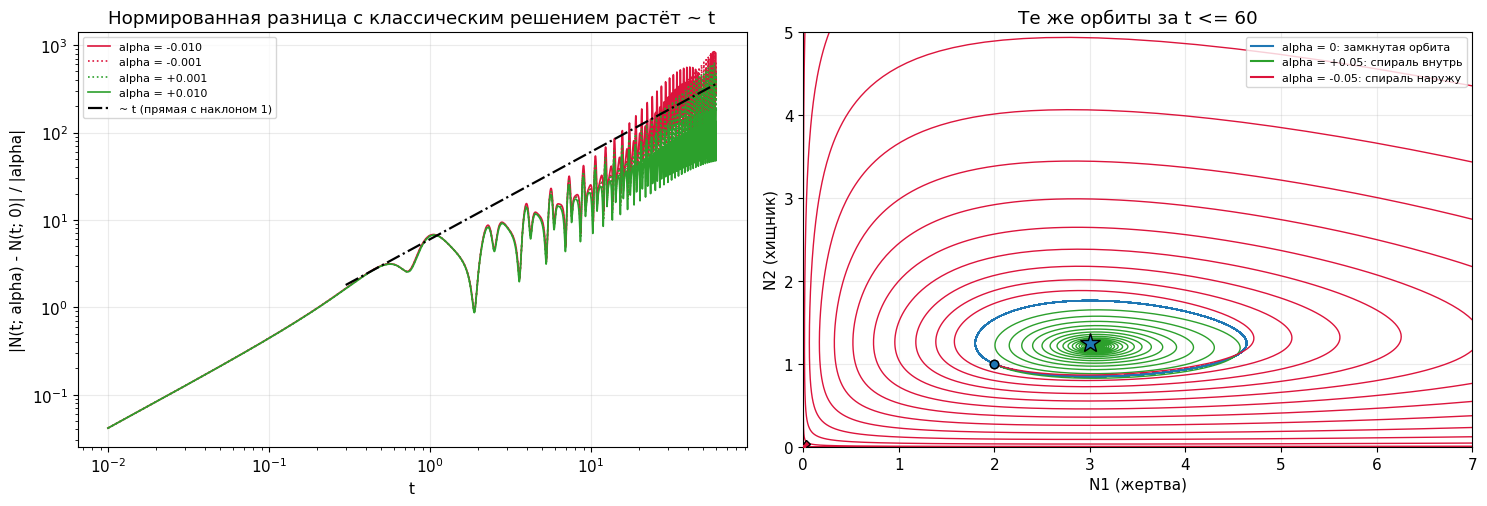

In [24]:
T_end = 60
t0, N1_0, N2_0, _ = solve_lv(0.0, IC, T_end, n=6001)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
styles = {-0.01: ('crimson', '-'), -0.001: ('crimson', ':'), 0.001: ('tab:green', ':'), 0.01: ('tab:green', '-')}
for a, (c, ls) in styles.items():
    t, N1, N2, tb = solve_lv(a, IC, T_end, n=6001)
    m = min(len(t), len(t0))
    d = np.hypot(N1[:m] - N1_0[:m], N2[:m] - N2_0[:m])/abs(a)          # разница, делённая на |alpha|
    ax[0].loglog(t[1:m], d[1:m], color=c, ls=ls, lw=1.2, label=f'alpha = {a:+.3f}')
tt = np.linspace(0.3, T_end, 100)
ax[0].loglog(tt, 6.0*tt, 'k-.', lw=1.6, label='~ t (прямая с наклоном 1)')
ax[0].set_xlabel('t'); ax[0].set_ylabel('|N(t; alpha) - N(t; 0)| / |alpha|')
ax[0].set_title('Нормированная разница с классическим решением растёт ~ t'); ax[0].legend(fontsize=8)
# фазовые портреты на длинном интервале
phase_axes(ax[1], 0.0, (0, 7), (0, 5), ics=[IC], T=T_end, field=False, nullclines=False, lw=1.0)
for a, c in [(0.05, 'tab:green'), (-0.05, 'crimson')]:
    t, N1, N2, tb = solve_lv(a, IC, T_end, n=9000)
    ax[1].plot(N1, N2, color=c, lw=1.0, label=f'alpha = {a:+.2f}')
ax[1].plot(*IC, 'ko')
ax[1].legend(handles=[Line2D([], [], color='tab:blue', label='alpha = 0: замкнутая орбита'),
                      Line2D([], [], color='tab:green', label='alpha = +0.05: спираль внутрь'),
                      Line2D([], [], color='crimson', label='alpha = -0.05: спираль наружу')], fontsize=8)
ax[1].set_title(f'Те же орбиты за t <= {T_end}')
plt.tight_layout(); plt.show()

**Наблюдения.**

* Разница между решением с поправкой и классическим решением, **поделённая на $|\alpha|$**, у кривых для $\alpha=\pm0{,}001$ и $\pm0{,}01$ почти совпадает и растёт примерно как $t$ (на двойной логарифмической шкале — прямая с наклоном 1). Значит, разница $\approx C\,|\alpha|\,t$: малая добавка **накапливается линейно во времени**, потому что она систематически сдвигает и фазу (период зависит от $\alpha$ линейно), и амплитуду (дрейф $V$ со скоростью $\propto\alpha$). Рост продолжается, пока разница не достигнет масштаба самой орбиты; при $\alpha=0{,}05$ это происходит уже за несколько десятков единиц времени.
* Замкнутая орбита классической модели при $\alpha=+0{,}05$ превращается в спираль внутрь, при $\alpha=-0{,}05$ — в спираль наружу. Орбита не «чуть искажается», а перестаёт быть замкнутой.

### 7.2. Как быстро проявляется поправка

Скорость изменения амплитуды определяется $T=-\alpha(N_1^*+N_2^*)$. Функция $V$ (примерно квадрат амплитуды) уменьшается вдвое за время $t_{1/2}=\ln2/|T|$ при $\alpha>0$ (при $\alpha<0$ удваивается). Переведём в число периодов $T_d$:

In [25]:
print(f'{"alpha":>8} {"T":>10} {"t_1/2 (V вдвое)":>17} {"период":>9} {"в периодах":>11}')
for a in [0.001, 0.01, 0.05, 0.18]:
    N, T_, D_, lam, kind = interior_info(a)
    Td = 2*np.pi/np.sqrt(D_ - T_**2/4)
    th = np.log(2)/abs(T_)
    print(f'{a:8.3f} {T_:10.4f} {th:17.2f} {Td:9.3f} {th/Td:11.1f}')

   alpha          T   t_1/2 (V вдвое)    период  в периодах
   0.001    -0.0043            163.07     1.622       100.5
   0.010    -0.0425             16.29     1.624        10.0
   0.050    -0.2136              3.24     1.631         2.0
   0.180    -0.7749              0.89     1.672         0.5


Даже поправка в **один процент** ($\alpha=0{,}01$) за время порядка 16 единиц (около десяти колебаний) уменьшает функцию $V$ вдвое. То есть периодичность классической модели сохраняется лишь на ограниченном числе периодов, пропорциональном $1/|\alpha|$; при строгом $\alpha=0$ она не затухает никогда.

### 7.3. Другие виды возмущения: поправки разной величины и знака в двух уравнениях

Рассмотрим более общее изменение: $-\alpha_1N_1^2$ в первом уравнении и $-\alpha_2N_2^2$ во втором, при этом $\alpha_1\ne\alpha_2$. Равновесие и матрица Якоби считаются по общим формулам из раздела 1 (функции принимают пару `(alpha1, alpha2)`); функция $V$ работает и здесь, только теперь $\dot V=-\alpha_1\gamma_2\Delta N_1^2-\alpha_2\gamma_1\Delta N_2^2$ (перекрёстные слагаемые по-прежнему сокращаются), а $T=-(\alpha_1N_1^*+\alpha_2N_2^*)$.

  (alpha1, alpha2)               N*        T                     lambda  тип
      (0.05, 0.05) (3.061, 1.212)  -0.2136 -0.107+3.851i,  -0.107-3.851i  устойчивый фокус
       (0.05, 0.0) (3.000, 1.212)  -0.1500 -0.075+3.814i,  -0.075-3.814i  устойчивый фокус
       (0.0, 0.05) (3.062, 1.250)  -0.0625 -0.031+3.913i,  -0.031-3.913i  устойчивый фокус
     (0.05, -0.05) (2.939, 1.213)  -0.0863 -0.043+3.775i,  -0.043-3.775i  устойчивый фокус
     (-0.05, 0.05) (3.064, 1.288)   0.0888 +0.044+3.972i,  +0.044-3.972i  неустойчивый фокус
    (-0.05, -0.05) (2.936, 1.287)   0.2111 +0.106+3.887i,  +0.106-3.887i  неустойчивый фокус


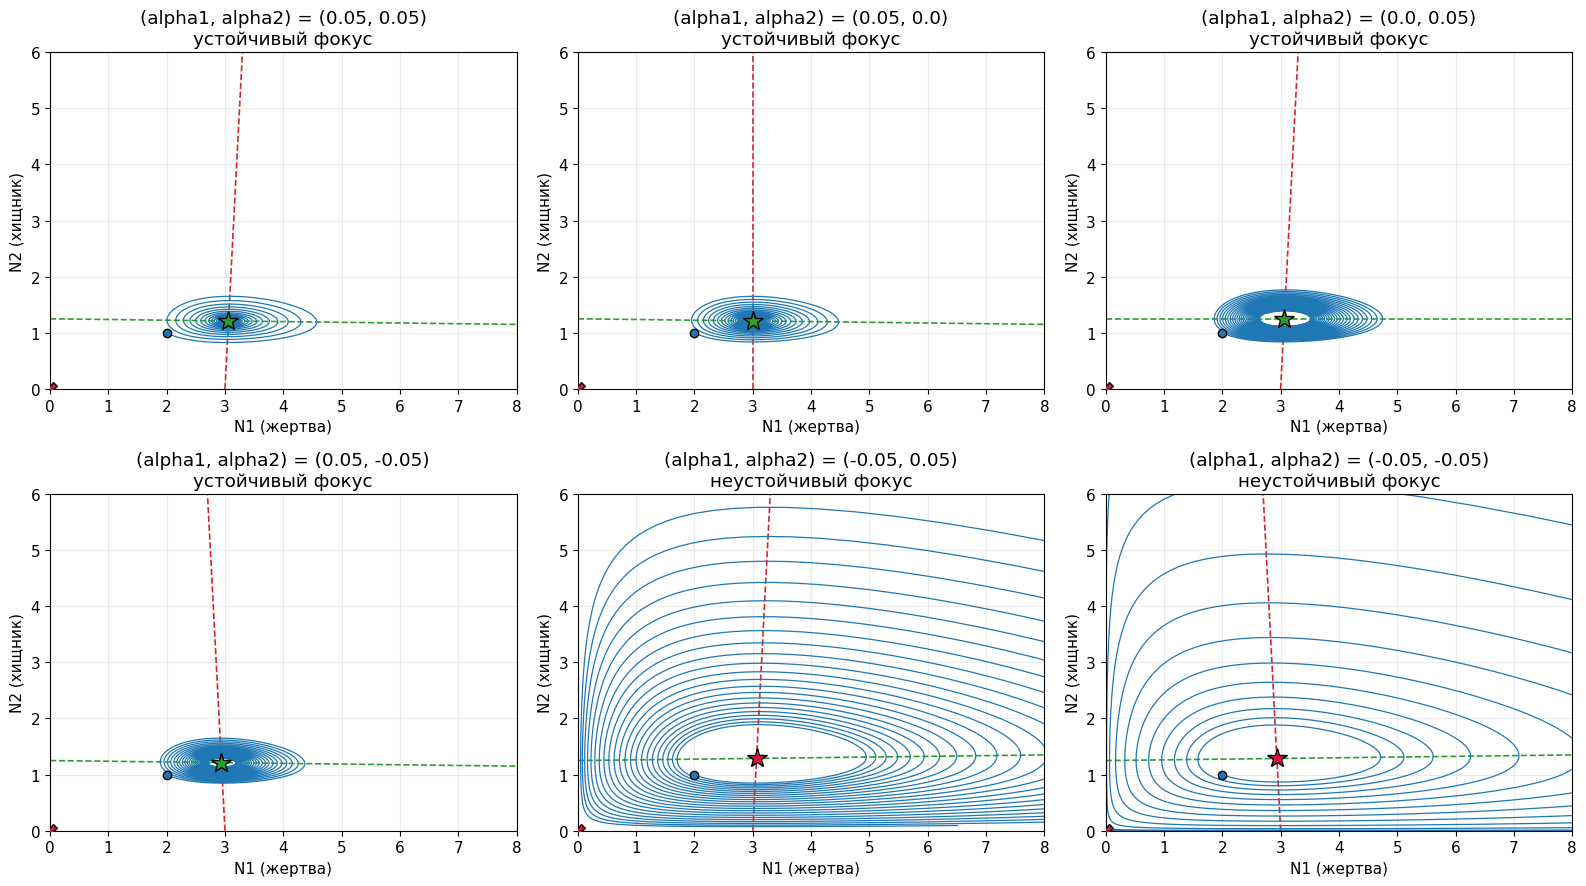

In [26]:
combos = [(0.05, 0.05), (0.05, 0.0), (0.0, 0.05), (0.05, -0.05), (-0.05, 0.05), (-0.05, -0.05)]
print(f'{"(alpha1, alpha2)":>18} {"N*":>16} {"T":>8} {"lambda":>26}  тип')
for pr in combos:
    N, T_, D_, lam, kind = interior_info(pr)
    print(f'{str(pr):>18} ({N[0]:.3f}, {N[1]:.3f}) {T_:8.4f} {fmt_lam(lam):>26}  {kind}')
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, pr in zip(axes.ravel(), combos):
    phase_axes(ax, pr, (0, 8), (0, 6), ics=[IC], T=40, field=False, nullclines=True, lw=0.9)
    N, T_, D_, lam, kind = interior_info(pr)
    ax.set_title(f'(alpha1, alpha2) = {pr}\n{kind}')
plt.tight_layout(); plt.show()

Для **любой** комбинации малых $\alpha_1,\alpha_2\ne0$ с $T\ne0$ центр исчезает: фокус устойчив при $T<0$ и неустойчив при $T>0$. Разное «направление» возмущения даёт разный результат: сравните $(0{,}05;\,0)$ и $(0;\,0{,}05)$ — поправка только для жертвы или только для хищника, а также $(0{,}05;\,-0{,}05)$ и $(-0{,}05;\,0{,}05)$, где знак результата зависит от того, какая популяция больше ($T\propto-(\alpha_1N_1^*+\alpha_2N_2^*)$). Центр сохраняется лишь при специальной настройке $\alpha_1N_1^*+\alpha_2N_2^*=0$ (условие на параметры, нарушаемое любым дальнейшим изменением), и даже тогда поведение определяется нелинейными слагаемыми.

### 7.4. Чувствительность к ошибкам численного метода

Классический центр чувствителен и к погрешности самого вычисления: ошибка метода действует как малое возмущение уравнения. Решим классическую модель разными методами и посмотрим на сохранение функции $V$ (она должна быть постоянна).

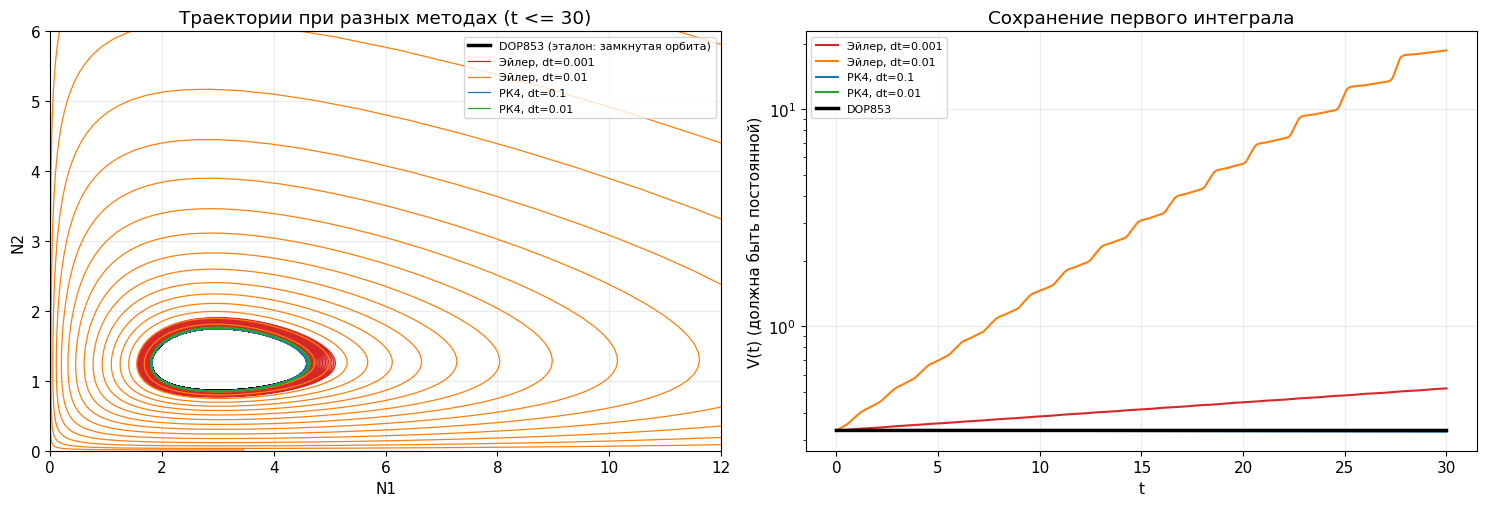

Эйлер, dt=0.001   : V(0) = 0.3321, V(30) = 0.5183
Эйлер, dt=0.01    : V(0) = 0.3321, V(30) = 18.6235
РК4, dt=0.1       : V(0) = 0.3321, V(30) = 0.3279
РК4, dt=0.01      : V(0) = 0.3321, V(30) = 0.3321


In [27]:
def euler_traj(ic, dt, T):
    N = np.array(ic, float); n = int(round(T/dt)); out = np.empty((n + 1, 2)); out[0] = N
    for i in range(n):
        N = N + dt*np.array([(eps1 - gam1*N[1])*N[0], (-eps2 + gam2*N[0])*N[1]]); out[i + 1] = N
    return out

def rk4_traj(ic, dt, T):
    f = lambda N: np.array([(eps1 - gam1*N[1])*N[0], (-eps2 + gam2*N[0])*N[1]])
    N = np.array(ic, float); n = int(round(T/dt)); out = np.empty((n + 1, 2)); out[0] = N
    for i in range(n):
        k1 = f(N); k2 = f(N + dt/2*k1); k3 = f(N + dt/2*k2); k4 = f(N + dt*k3)
        N = N + dt/6*(k1 + 2*k2 + 2*k3 + k4); out[i + 1] = N
    return out

T_long = 30
t_ref, N1_ref, N2_ref, _ = solve_lv(0.0, IC, T_long, n=6001)
runs = {'Эйлер, dt=0.001': (euler_traj(IC, 1e-3, T_long), 1e-3), 'Эйлер, dt=0.01': (euler_traj(IC, 1e-2, T_long), 1e-2),
        'РК4, dt=0.1': (rk4_traj(IC, 0.1, T_long), 0.1), 'РК4, dt=0.01': (rk4_traj(IC, 0.01, T_long), 0.01)}
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
ax[0].plot(N1_ref, N2_ref, 'k', lw=2.5, label='DOP853 (эталон: замкнутая орбита)')
cols = ['tab:red', 'tab:orange', 'tab:blue', 'tab:green']
for (name, (o, dt)), c in zip(runs.items(), cols):
    ax[0].plot(o[:, 0], o[:, 1], color=c, lw=0.9, label=name)
    tt = np.arange(len(o))*dt
    ax[1].semilogy(tt, V_lyap(o[:, 0], o[:, 1], 0.0), color=c, label=name)
ax[1].semilogy(t_ref, V_lyap(N1_ref, N2_ref, 0.0), 'k', lw=2.5, label='DOP853')
ax[0].set_xlim(0, 12); ax[0].set_ylim(0, 6); ax[0].set_xlabel('N1'); ax[0].set_ylabel('N2'); ax[0].legend(fontsize=8)
ax[0].set_title('Траектории при разных методах (t <= 30)')
ax[1].set_xlabel('t'); ax[1].set_ylabel('V(t) (должна быть постоянной)'); ax[1].legend(fontsize=8)
ax[1].set_title('Сохранение первого интеграла')
plt.tight_layout(); plt.show()
for name, (o, dt) in runs.items():
    V = V_lyap(o[:, 0], o[:, 1], 0.0)
    print(f'{name:18s}: V(0) = {V[0]:.4f}, V(30) = {V[-1]:.4f}')

Явный метод Эйлера вносит ошибку, которая действует как **антидиссипация**: орбита превращается в раскручивающуюся спираль, $V$ растёт (при $dt=0{,}01$ — более чем в 50 раз за $t=30$). Метод Рунге–Кутты 4-го порядка сохраняет $V$ гораздо точнее, но тоже не идеально при большом шаге. Ошибка метода — ещё одно «малое изменение вида уравнений», и классическая модель на неё реагирует так же, как на $\alpha\ne0$: **замкнутые орбиты не воспроизводятся численно «бесплатно»**. Поэтому для классической модели нужны методы высокого порядка (или симплектические/сохраняющие интеграл схемы) и малые допуски.

### 7.5. Вывод о чувствительности (пункт 3)

Классическая модель Лотки–Вольтерры **структурно неустойчива (негрубая)**:

1. **Любая** малая поправка, нарушающая сохранение первого интеграла (логистическая с любым $\alpha\ne0$, разные поправки в двух уравнениях, ошибка численного метода), **разрушает замкнутые орбиты**: центр превращается в устойчивый (при $T<0$) или неустойчивый (при $T>0$) фокус. Качественная картина меняется скачком при переходе через $\alpha=0$.
2. **Масштаб времени** проявления поправки $\sim1/|\alpha|$: чем она меньше, тем дольше сохраняется «почти периодичность», но при $t\to\infty$ поведение принципиально иное. Разница с классическим решением накапливается примерно линейно по $\alpha t$.
3. Следовательно, **периодические колебания с амплитудой, зависящей от начальных условий, — свойство идеализации**, а не устойчивый результат модели. Реалистичные эффекты (самоограничение, изъятие, насыщение) либо гасят колебания и приводят к устойчивому сосуществованию ($\alpha>0$), либо ведут к неограниченному росту ($\alpha<0$ без насыщения). В модели, претендующей на описание реальных популяций, колебания должны быть **устойчивыми** (предельный цикл), а не нейтральными, как в классической постановке.
4. Качественные выводы классической модели (существование периодического обмена между жертвой и хищником, сдвиг фаз на четверть периода, седло в нуле) устойчивы, но **количественные** (амплитуда, период, даже сам факт замкнутости) — нет.

---
## 8. Общие выводы и что включить в отчёт

### 8.1. Выводы (пункты 2 и 3 задания)

**Пункт 2 — характер стационарной точки и свойства решений при $\alpha$ противоположных знаков.**

* Внутренняя стационарная точка $N^*=\big(\frac{\alpha\varepsilon_1+\gamma_1\varepsilon_2}{\alpha^2+\gamma_1\gamma_2},\ \frac{\gamma_2\varepsilon_1-\alpha\varepsilon_2}{\alpha^2+\gamma_1\gamma_2}\big)$ (для варианта 10: $(3{,}199;\ 1{,}106)$ при $\alpha=0{,}18$) является **фокусом** при всех $\alpha\in[-1,1]$, $\alpha\ne0$, и **центром** при $\alpha=0$.
* $\alpha>0$: **устойчивый фокус**; $V$ убывает; колебания затухают; все положительные решения сходятся к $N^*$ (устойчивое сосуществование).
* $\alpha<0$: **неустойчивый фокус**; $V$ растёт; колебания нарастают; жертва стремится к нулю, хищник за конечное время «взрывается».
* Остальные особые точки в квадранте — седла (начало координат и осевая точка), они не влияют на асимптотику.

**Пункт 3 — чувствительность классической модели.** Структурная неустойчивость: любое малое возмущение вида уравнений (логистическая поправка, разные поправки, даже погрешность численного метода) разрушает семейство замкнутых орбит; время проявления $\sim1/|\alpha|$.

### 8.2. Что включить в отчёт

1. Постановка: система, параметры варианта 10.
2. Особые точки (формулы), матрица Якоби, $T$, $D$, собственные значения и тип точек; условие существования внутренней точки.
3. Функция Ляпунова $V$ и формула $\dot V=-\alpha(\gamma_2\Delta N_1^2+\gamma_1\Delta N_2^2)$ (вывод в разделе 1.4).
4. Графики $N_1(t)$, $N_2(t)$ и фазовые портреты для $\alpha\in[-1,1]$ (раздел 5), отдельно для $\alpha=0{,}18$ (раздел 4).
5. Сравнение $\alpha>0$ и $\alpha<0$ (раздел 6) и таблица выводов.
6. Анализ классической модели и заключение о её чувствительности (разделы 2 и 7).

### Приложение. Как изменить вариант, начальные условия и параметры

* **Вариант:** поменяйте `VARIANT` в ячейке «Параметры» (1–20). Все числа в таблицах и на графиках пересчитаются; числа, процитированные в тексте, относятся к варианту 10.
* **Начальные условия:** `IC` (основное) и `ICS` (набор для фазовых портретов). Для расчёта вблизи равновесия используйте точки вида `(N1*+dev, N2*)`.
* **Значения $\alpha$:** список `ALPHAS`.
* **Окна фазовых портретов:** аргументы `xlim`, `ylim` в вызовах `phase_axes`. При больших параметрах (например, вариант 7) окно $(0;8)\times(0;6)$ может быть мало: увеличьте его.
* **Если взрыв при $\alpha<0$ слишком быстрый** и график выглядит «обрезанным»: это нормально; счёт останавливается при $\max N_i>10^6$ (аргумент `Nmax` функции `solve_lv`).
* **Ошибка `ModuleNotFoundError`:** установите недостающую библиотеку (`pip install numpy scipy matplotlib sympy`).